# APTOS 2019 — S0-v1.0 · QĐ22 / N25 / N26 (Review 03-11-2026)

**Notebook kế thừa trực tiếp `Code split(2).ipynb`**, giữ nguyên kiểm toán pixel SHA-256, so khớp hai góc nhìn, SSIM/NCC/IoU, xử lý cụm đã xác nhận và baseline chỉ dùng metadata. Không tự gán nhãn A/B/C bằng độ tương đồng.

**Hai giai đoạn bắt buộc:**
1. **DRAFT**: Chạy toàn bộ notebook, lấy `data_quality/near_duplicate_review_v1_template.csv`, kiểm tra bằng mắt và điền người xem/ngày/loại A-B-C; nếu có bảng xếp hạng từ `ManualCheckDuplicate.ipynb` phải khai báo `ranked_pairs_csv` để giữ đúng thứ tự lịch sử. Notebook tạo sẵn 1.000 cặp đầu + mẫu 200 cặp từ hạng 1.001–10.000. *Không được tự coi 1.000 cặp đã xem là đã có nhật ký.*
2. **CANDIDATE → FROZEN**: Chạy lại cùng nguồn dữ liệu với `bounded_review_log_csv` đã điền; kiểm tra thống kê, các cặp mới xác nhận và SHA; nộp giảng viên duyệt. Chỉ khi có `advisor_approval_ref` và thư mục archive bộ chia 13/10 hợp lệ mới xuất trạng thái `approved_frozen`.

**Quy tắc QĐ22:** A cùng ảnh **khác Grade** → loại cả cụm A/exact; A cùng Grade và B (cùng mắt khác lần chụp, kể cả khác Grade) → giữ trong **cùng partition**; C → không nối nhóm. B không tự bị loại khi khác Grade. `pHash/dHash` chỉ là ứng viên rà soát, tuyệt đối không nối tự động. Không có patient ID, không tuyên bố patient-disjoint.

**Yêu cầu môi trường:** `scikit-learn >= 1.8.0` (phiên bản thấp hơn bị lỗi khi `StratifiedGroupKFold(shuffle=True)`). Nếu Kaggle chưa đạt, cài lại qua `pip install -U 'scikit-learn>=1.8,<2'`, restart session rồi chạy từ đầu. Notebook không tự thay môi trường hoặc tải Internet.

**Cách dùng nhanh:** đặt đường dẫn ở CONFIG → Run All → xem `splits/partition_counts.csv` + `reports/validation_checks.json` → điền nhật ký → Run All để cập nhật. Không huấn luyện mô hình DR ảnh trước khi M0 được duyệt. Không thay thế fold 70/10/20 bằng random split theo ảnh.

In [55]:

%pip install -q --upgrade "scikit-learn>=1.8,<2"

Note: you may need to restart the kernel to use updated packages.


In [56]:
from pathlib import Path
CONFIG = {
    'data_root': '/kaggle/input',
    'train_csv': "/kaggle/input/competitions/aptos2019-blindness-detection/train.csv",             # Tự dò train.csv duy nhất bên dưới data_root
    'image_dir': "/kaggle/input/competitions/aptos2019-blindness-detection/train_images",             # Tự dò train_images/ của APTOS
    'output_dir': '/kaggle/working/aptos_s0_manual_review',
    'review_csv': None,            # Tùy chọn: CSV quyết định B/C hoặc các cặp mới, KHÔNG lặp lại 15 cặp đã nhúng
    'conflict_review_csv': None,   # Tùy chọn: quyết định B_grade_difference nếu phát sinh
    'seed': 42, 'n_folds': 5, 'validation_fraction_remaining': 0.125,
    'strict_aptos_inventory': True,
    'invalid_image_policy': 'error',
    'acquisition_min_count': 30, 'stratum_min_count': 10,
    'compare_size': 128, 'mask_threshold': 8, 'min_mask_fraction': 0.10,
    'hamming_thresholds': [4, 6, 8, 10],
    # Chỉ xếp ưu tiên rà soát; KHÔNG gộp cụm theo ngưỡng tự động.
    'review_priority_thresholds': {'phash_max': 6, 'dhash_max': 6,
                                  'ssim_min': 0.94, 'ncc_min': 0.97, 'mask_iou_min': 0.90},
    'image_lru_size': 128, 'metric_commit_every': 500, 'cpu_threads': 2,
    'contact_sheet_pair_limit': 120, 'pairs_per_sheet': 6,
    'logistic_C': 1.0, 'logistic_max_iter': 3000,
    'run_unit_tests': True,
}
# QĐ22/N25/N26 — cấu hình mới (giữ nguyên 15 quyết định đã đối chiếu SHA)
CONFIG.update({
    'output_dir': '/kaggle/working/aptos_s0_v1_work',
    'ranked_pairs_csv': None,            # Tùy chọn: bảng rank,pair_id lấy từ notebook xếp hạng cũ
    'bounded_review_log_csv': None,      # CSV 1.000 + 200 cặp đã phân loại THỦ CÔNG
    'bounded_review_top_n': 1000,
    'bounded_review_sample_n': 200,
    'bounded_review_sample_first_rank': 1001,
    'bounded_review_sample_last_rank': 10000,
    'bounded_review_seed': 20261103,
    'max_outer_grade_deviation_pp': 1.0,
    'max_outer_acquisition_deviation_pp': 1.0,
    'expected_s0_n_reference': 3583,    # Tham chiếu phiên bản ban đầu; thay đổi do review cần báo cáo
    'expected_s0_grade_reference': {0:1801,1:360,2:975,3:172,4:275},
    'legacy_20261013_dir': None,         # Đường dẫn thư mục bản split 13/10 để lưu vào archive (nếu có)
    'advisor_approval_ref': None,        # Chỉ điền link/mã xác nhận SAU KHI cô duyệt
    'version_label': 'S0-v1.0',
})
PIPELINE_VERSION = 'aptos-audit-s0-qD22-n25-n26-3.0.0'
MANUAL_EVIDENCE_DOC = 'https://docs.google.com/document/d/19mI5upl7mdwM-Jkp28kpvv2dgprP_pCIT6kDWw_eTOc/edit'
# Các bản ghi này được đối chiếu giữa tài liệu người nghiên cứu và CSV đã xác nhận.
# expected_pair_id và pixel SHA-256 dùng để ngăn nhận nhầm phiên dữ liệu.
MANUAL_REVIEW_15 = [{'rank': 1, 'id_1': '3435fd8675a2', 'id_2': 'c62585bd68fb', 'grade_1': 3, 'grade_2': 4, 'expected_pair_id': 'aa405a444a58fd4f260ce6bf16f500bb1c54ff9290d62a5a1847226801a06207', 'expected_pixel_sha256_1': 'fe876f98178b63c66e14ec5ce7e95ba14ab0b0e9e386ab078f6ac077e3603239', 'expected_pixel_sha256_2': 'cd4834ac69c1fd4f2950a074298d26ea814f9c6f36ae04bcd802bab14265da0d'}, {'rank': 2, 'id_1': '33778d136069', 'id_2': '4ccfa0b4e96c', 'grade_1': 3, 'grade_2': 4, 'expected_pair_id': 'd07dc2903e208d911433196cd0556bed843e3587eb94c5e0c96aca118e81444c', 'expected_pixel_sha256_1': '8d2bc7ff3fb995c2e2eca16e603f76a18850b59a4a2e67af56f2572799f6dad1', 'expected_pixel_sha256_2': 'cb8d618387dceeb6ffa3929de2bdbfadb346c4c997675adcf79da00c4e539e91'}, {'rank': 3, 'id_1': '2b48daf24be0', 'id_2': '9a94e0316ee3', 'grade_1': 3, 'grade_2': 3, 'expected_pair_id': 'c89ec09b9397cc120f7d38b5e663ca52dfa2940682fa3a2fcbe0f7e263e36961', 'expected_pixel_sha256_1': '982dddf2099c397753c2200bb7ff7bcd9da4ab153ac7a04f272f326b5160d6a4', 'expected_pixel_sha256_2': '6b2a2ea785b1f0f6896748ab64d84d717cb68778e884229353b1cb58fe3a9dfd'}, {'rank': 4, 'id_1': '60f15dd68d30', 'id_2': '772af553b8b7', 'grade_1': 4, 'grade_2': 3, 'expected_pair_id': '92f1cbde3ca6fa9fd4d781fb263484008274b799468ba40e181d4f33d2d3545b', 'expected_pixel_sha256_1': 'f9522551cd2d9d812e1d2100ac35059430c9752ffcad0aaec91ed00d03165488', 'expected_pixel_sha256_2': 'abd1d30cbd2ba5395b679d4e32d02d300a008f067edbcaaf0d9292f090491ca9'}, {'rank': 5, 'id_1': '772af553b8b7', 'id_2': 'fcc6aa6755e6', 'grade_1': 3, 'grade_2': 3, 'expected_pair_id': '00f4721d82731af0ad8e306e3e9ae80e2954acbc69a6af0dc69c2c5fa134c4af', 'expected_pixel_sha256_1': 'abd1d30cbd2ba5395b679d4e32d02d300a008f067edbcaaf0d9292f090491ca9', 'expected_pixel_sha256_2': 'f9522551cd2d9d812e1d2100ac35059430c9752ffcad0aaec91ed00d03165488'}, {'rank': 6, 'id_1': '16ce555748d8', 'id_2': '4d9fc85a8259', 'grade_1': 4, 'grade_2': 3, 'expected_pair_id': 'f4cf5ecbfc33c17d2dc89911d3dd75e8c57f81b96b87aa7fa26d384d1c2b2986', 'expected_pixel_sha256_1': '8a38c9a2c50a3ebdb83fe70602cb5b9bf2f3a9cb7346461c4c9a19917ec937a5', 'expected_pixel_sha256_2': '763511f6c3007b05233a023078ba075fee0d37c7f20f4f5dacaa7d8f33422cda'}, {'rank': 7, 'id_1': 'b019a49787c1', 'id_2': 'e1fb532f55df', 'grade_1': 3, 'grade_2': 3, 'expected_pair_id': '215191babb13d80ed03981a5cdd49e421b0bd0d03cc2e9073e556664b7505048', 'expected_pixel_sha256_1': 'c2b86fef8c6d74f82c26c105794b87920493481fa9e537b65905ff4c13796b4c', 'expected_pixel_sha256_2': 'd89e270c55c1f725e6008ed9c2e3bbd3025bbc94e2c26cdb2b6996dcde652321'}, {'rank': 8, 'id_1': '2f284b6a1940', 'id_2': 'bb5083fae98f', 'grade_1': 4, 'grade_2': 3, 'expected_pair_id': 'c58b93b7d8347d6a46c5ac6670179de70790e37463cb825438b22ee11560e730', 'expected_pixel_sha256_1': '34e588a7e570606e01a9020bb3be3b9b6208120b1b9f4a5b024faf640499a474', 'expected_pixel_sha256_2': 'a0ea292b1a52fecad3e5f59fd13811bb55b3e180036b7f9169eb6341d046e755'}, {'rank': 9, 'id_1': '8688f3d0fcaf', 'id_2': 'bfefa7344e7d', 'grade_1': 3, 'grade_2': 4, 'expected_pair_id': '509e787e19fba39094811431a70bac04d01a322cc99e84b00b3be3239383e8a7', 'expected_pixel_sha256_1': '717f332e513bf07a8cf361718e4f6565c796ea4a2a71a49a1a07e3414865ff52', 'expected_pixel_sha256_2': '146364253bad79cc22638f3004f2bdbee685124a0408ad484ae3028aeab74c0b'}, {'rank': 10, 'id_1': '8688f3d0fcaf', 'id_2': 'd85ea1220a03', 'grade_1': 3, 'grade_2': 4, 'expected_pair_id': 'e4f9588285170660880fe0ed3db7aca19b3b395774ef1e720836946a73a23201', 'expected_pixel_sha256_1': '717f332e513bf07a8cf361718e4f6565c796ea4a2a71a49a1a07e3414865ff52', 'expected_pixel_sha256_2': '146364253bad79cc22638f3004f2bdbee685124a0408ad484ae3028aeab74c0b'}, {'rank': 11, 'id_1': '3b018e8b7303', 'id_2': '3ddb86eb530e', 'grade_1': 3, 'grade_2': 2, 'expected_pair_id': 'c4123378a2858fe2e0b6729c146ca9e311b63c7751d2fca945f9448833f7252d', 'expected_pixel_sha256_1': '4881d863379a314b43b95acb64f4a9aff8d28f624946d832be2eae8fcaf43b9d', 'expected_pixel_sha256_2': '0851eddfa30bc909fa728dd1417b519e8b3bc89334f174210c407e767e17de63'}, {'rank': 12, 'id_1': 'cd93a472e5cd', 'id_2': 'd035c2bd9104', 'grade_1': 4, 'grade_2': 3, 'expected_pair_id': 'ed8d9cd794c836ab771773ce21787c49f44f426ff2614ab42b08860253b33fa9', 'expected_pixel_sha256_1': '8ee7b08892d26725a2978dcc325c6cdeb006289e7e350d54968b47f07f32c378', 'expected_pixel_sha256_2': 'c3047d429fb982304449e4e9f052f69407c061fb3ea5315934352d2f448cdb5f'}, {'rank': 13, 'id_1': '0243404e8a00', 'id_2': '3ddb86eb530e', 'grade_1': 4, 'grade_2': 2, 'expected_pair_id': '611ca3725b02fa6c0da26aea6e20e0d722b056019386ca1e14f11ccd4abbbd48', 'expected_pixel_sha256_1': '40cda4f756decc633c9967884b0d643c905a120cb29e8bb4653fedfaef72ee73', 'expected_pixel_sha256_2': '0851eddfa30bc909fa728dd1417b519e8b3bc89334f174210c407e767e17de63'}, {'rank': 14, 'id_1': '0243404e8a00', 'id_2': '3b018e8b7303', 'grade_1': 4, 'grade_2': 3, 'expected_pair_id': 'f231eac1f4d1cd4ab50c9d6972d26f5c11c5a5e333aae40ef47dbcf61f8b33cd', 'expected_pixel_sha256_1': '40cda4f756decc633c9967884b0d643c905a120cb29e8bb4653fedfaef72ee73', 'expected_pixel_sha256_2': '4881d863379a314b43b95acb64f4a9aff8d28f624946d832be2eae8fcaf43b9d'}, {'rank': 133, 'id_1': '2fdfb80ea53c', 'id_2': '535682537302', 'grade_1': 0, 'grade_2': 0, 'expected_pair_id': 'e6c0818030373ba887f2a0eee1e9e467e126c8116c9650081a0be499d68dd25e', 'expected_pixel_sha256_1': '84ac40ff6ee0c0ef469b7b45a8c28901ed2c30e742f98ec6c952716e6b06e4d2', 'expected_pixel_sha256_2': '9cf5f7ac7bb41cf98faa2d579138df2897bb19e9a796f0c9490e9bcbe2126988'}]


In [57]:

from pathlib import Path
import pandas as pd

csv_path = Path(
    "/kaggle/input/datasets/bondyyyyy/nearduplicatemanual/near_duplicate_review_v1 (1).csv"
)

assert csv_path.is_file(), f"Không tìm thấy CSV: {csv_path}"

review = pd.read_csv(
    csv_path,
    dtype=str,
    keep_default_na=False
)

# Kiểm tra CSV mới nhất
assert len(review) == 1200
assert review["pair_id"].nunique() == 1200
assert review["classification"].value_counts().to_dict() == {
    "A": 16,
    "C": 1184
}
assert review["review_date"].str.strip().ne("").all()

CONFIG["bounded_review_log_csv"] = str(csv_path)

print("CSV hợp lệ:", csv_path)
print("Số cặp:", len(review))
print("Phân loại:")
print(review["classification"].value_counts())
print("Tất cả có ngày đánh giá: YES")


CSV hợp lệ: /kaggle/input/datasets/bondyyyyy/nearduplicatemanual/near_duplicate_review_v1 (1).csv
Số cặp: 1200
Phân loại:
classification
C    1184
A      16
Name: count, dtype: int64
Tất cả có ngày đánh giá: YES


## 1. Môi trường, log và lưu an toàn
Input: cấu hình. Output: thư mục, cấu hình và phiên bản thư viện. Không pip install / Internet.
Cache kiểm tra SHA-256 file nguồn mỗi lần chạy; thay ảnh hoặc tham số tiền xử lý sẽ vô hiệu cache.
Đầu mỗi lần chạy vô hiệu kết quả xuất bản cũ; lỗi giữa chừng không để lại trạng thái “đạt”.

In [58]:
import os, sys, json, hashlib, logging, platform, random, sqlite3, warnings, time
from collections import Counter
from functools import lru_cache
from itertools import combinations
from importlib.metadata import version, PackageNotFoundError

REQUIRED = ['numpy', 'pandas', 'Pillow', 'scipy', 'scikit-learn', 'scikit-image', 'matplotlib', 'tqdm']
versions = {}
for package in REQUIRED:
    try: versions[package] = version(package)
    except PackageNotFoundError as e:
        raise RuntimeError(f'Thiếu {package}. Dùng Kaggle Python image có sẵn thư viện này; notebook không tải Internet.') from e
import sklearn
from packaging.version import Version
if Version(sklearn.__version__) < Version('1.8.0'):
    raise RuntimeError(f'QĐ22/N25: scikit-learn {sklearn.__version__} có lỗi SGKF shuffle=True. '
                       'Cài scikit-learn>=1.8,<2 và restart kernel rồi chạy lại.')
import numpy as np
import pandas as pd
from PIL import Image
from scipy.fft import dctn
from scipy.ndimage import binary_fill_holes, binary_erosion, label
from skimage.metrics import structural_similarity
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix
from threadpoolctl import threadpool_limits
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed'])
_thread_limit = threadpool_limits(limits=CONFIG['cpu_threads'])
OUT = Path(CONFIG['output_dir']).resolve()
ROOT = Path(CONFIG['data_root']).resolve()
if OUT == ROOT or ROOT in OUT.parents:
    raise ValueError('output_dir không được nằm trong data_root.')
# Chặn ghi đè bản đã khóa từ lần chạy trước (kể cả khi khởi chạy lại).
if (OUT/'splits/OFFICIAL_READY.json').exists():
    raise FileExistsError(f'{OUT} đã có S0 được khóa. Đổi CONFIG["output_dir"] để làm phiên bản khác.')
for sub in ['data_quality' , 'splits', 'figures/duplicate_pairs', 'figures/conflict_pairs',
            'reports', 'reproducibility', 'cache/images']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
logger = logging.getLogger('aptos_audit'); logger.handlers.clear(); logger.setLevel(logging.INFO)
for handler in [logging.StreamHandler(sys.stdout), logging.FileHandler(OUT/'reports/pipeline.log', mode='w')]:
    handler.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
    logger.addHandler(handler)
WRITTEN = set()
def clean_json(obj):
    if isinstance(obj, dict): return {str(k): clean_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set, np.ndarray)): return [clean_json(v) for v in obj]
    if isinstance(obj, (np.integer,)): return int(obj)
    if isinstance(obj, (np.bool_,)): return bool(obj)
    if isinstance(obj, (float, np.floating)): return float(obj) if np.isfinite(obj) else None
    if isinstance(obj, Path): return str(obj)
    return obj
def digest_obj(obj):
    return hashlib.sha256(json.dumps(clean_json(obj), sort_keys=True, ensure_ascii=False).encode()).hexdigest()
def sha_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
def save_json(obj, rel):
    p = OUT/rel; p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix+'.tmp')
    tmp.write_text(json.dumps(clean_json(obj), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    os.replace(tmp, p); WRITTEN.add(rel)
def save_csv(df, rel):
    p = OUT/rel; p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix+'.tmp'); df.to_csv(tmp, index=False)
    os.replace(tmp, p); WRITTEN.add(rel)
def save_fig(fig, rel):
    fig.savefig(OUT/rel, dpi=150, bbox_inches='tight'); plt.close(fig); WRITTEN.add(rel)
def require(ok, message):
    if not bool(ok):
        save_json({'status':'failed', 'error':message}, 'reports/run_state.json')
        raise AssertionError(message)

save_json({'status':'running', 'official':False}, 'reports/run_state.json')
save_json({'status':'invalidated_by_new_run', 'official':False, 'scenarios':{}}, 'splits/splits.json')
save_json(CONFIG, 'reproducibility/config.json')
save_json({'pipeline_version':PIPELINE_VERSION, 'python':sys.version, 'platform':platform.platform(),
           'packages':versions, 'cpu_count':os.cpu_count(), 'seed':CONFIG['seed']}, 'reproducibility/environment.json')
T0 = time.monotonic()
logger.info('Khởi tạo %s; chỉ CPU; không huấn luyện mô hình ảnh.', PIPELINE_VERSION)

2026-11-03 19:20:30,804 | INFO | Khởi tạo aptos-audit-s0-qD22-n25-n26-3.0.0; chỉ CPU; không huấn luyện mô hình ảnh.


## 2. Khám phá và kiểm tra nguồn
Input: train.csv / train_images. Output: danh sách ID duy nhất và kiểm tra phân bố thực tế.
Nhiều nguồn phù hợp → yêu cầu chỉ rõ biến cấu hình, không tự chọn ngẫu nhiên. Test gốc không nhập.

In [59]:
def resolve_input():
    csv_path = Path(CONFIG['train_csv']).resolve() if CONFIG['train_csv'] else None
    if csv_path is None:
        matches = []
        for p in sorted(ROOT.rglob('train.csv')):
            try:
                sample = pd.read_csv(p, nrows=3)
                if {'id_code', 'diagnosis'} <= set(sample.columns): matches.append(p)
            except Exception: pass
        require(len(matches)==1, f'Tìm thấy {len(matches)} train.csv phù hợp: {matches}. Đặt CONFIG["train_csv"].')
        csv_path = matches[0]
    require(csv_path.is_file(), f'Không có train.csv: {csv_path}')
    table = pd.read_csv(csv_path, dtype={'id_code':str})
    require({'id_code','diagnosis'} <= set(table), 'CSV phải có id_code và diagnosis.')
    require(table.id_code.notna().all() and table.id_code.is_unique, 'ID trống hoặc trùng trong CSV.')
    require(table.id_code.str.fullmatch(r'[A-Za-z0-9_-]+').all(), 'ID chứa ký tự đường dẫn/không hợp lệ.')
    grade = pd.to_numeric(table.diagnosis, errors='coerce')
    require(grade.notna().all() and grade.isin(range(5)).all(), 'Grade phải là số nguyên 0–4.')
    table['grade'] = grade.astype(int)
    table = table.sort_values('id_code').reset_index(drop=True)
    image_dir = Path(CONFIG['image_dir']).resolve() if CONFIG['image_dir'] else None
    if image_dir is None:
        dirs = sorted(set(p for p in csv_path.parent.rglob('train_images') if p.is_dir()))
        require(len(dirs)==1, f'Tìm thấy {len(dirs)} thư mục train_images. Đặt CONFIG["image_dir"].')
        image_dir = dirs[0]
    require(image_dir.is_dir(), f'Thư mục ảnh không tồn tại: {image_dir}')
    index = {}
    for p in sorted(image_dir.rglob('*')):
        if p.is_file() and p.suffix.lower() in {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}:
            index.setdefault(p.stem, []).append(p)
    ambiguous = {i: [str(p) for p in index[i]] for i in table.id_code if len(index.get(i,[]))>1}
    require(not ambiguous, f'Một ID có nhiều file ảnh: {list(ambiguous.items())[:5]}')
    table['path'] = [str(index[i][0]) if i in index else '' for i in table.id_code]
    counts = table.grade.value_counts().sort_index().to_dict()
    expected = {0:1805,1:370,2:999,3:193,4:295}
    inventory = {'csv':str(csv_path), 'image_dir':str(image_dir), 'n':len(table),
                 'grade_counts':counts, 'expected_grade_counts':expected,
                 'matches_expected':len(table)==3662 and counts==expected,
                 'ignored_image_files_not_in_csv':sum(len(v) for k,v in index.items() if k not in set(table.id_code)),
                 'original_kaggle_test_imported':False, 'csv_sha256':sha_file(csv_path)}
    save_json(inventory, 'reports/input_inventory.json')
    if CONFIG['strict_aptos_inventory']:
        require(inventory['matches_expected'], 'Số lượng/phân bố không khớp APTOS gốc. Xem input_inventory.json; không tự bỏ qua.')
    logger.info('Nguồn: %s; %d ID; Grade=%s', csv_path, len(table), counts)
    return table, inventory

source, inventory = resolve_input()

2026-11-03 19:20:35,636 | INFO | Nguồn: /kaggle/input/competitions/aptos2019-blindness-detection/train.csv; 3662 ID; Grade={0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}


## 3. Manifest, pixel SHA-256 và ảnh so sánh có cache
Input: từng ảnh gốc. Output: metadata + cache mask/ảnh xám 128² + 2 view pHash/dHash 64 bit.
Hash pixel RGB đã giải mã (palette/gray được chuẩn hóa RGB 8 bit), kèm shape/dtype;
không EXIF transpose, không resize trước exact hash. Dữ liệu ngoài RGB/gray/palette 8 bit báo lỗi.
Phát hiện foreground trên thumbnail, lấy thành phần lớn nhất và lấp lỗ; crop rồi resize.
So sánh dùng kênh xanh, chuẩn hóa percentile trong mask để giảm ảnh hưởng sáng/tương phản.
View thứ hai crop tâm 90% giúp sàng lọc một số khác biệt crop, không bảo đảm recall tuyệt đối.

In [60]:
PREPROC = {k:CONFIG[k] for k in ['compare_size','mask_threshold','min_mask_fraction']}
PREPROC.update({'version':'fundus-comparison-algorithm-v2.0.0', 'hash_views':['fundus','center90'],
                'packages':{k:versions[k] for k in ['numpy','Pillow','scipy','scikit-image']}})
PREPROC_KEY = digest_obj(PREPROC)
def pixel_hash(rgb):
    a = np.ascontiguousarray(rgb)
    h = hashlib.sha256(json.dumps({'shape':list(a.shape),'dtype':a.dtype.str}, sort_keys=True).encode()+b'\0')
    h.update(a.tobytes()); return h.hexdigest()
def bits_hex(bits):
    value = 0
    for bit in np.asarray(bits).ravel(): value = (value << 1) | int(bit)
    return f'{value:016x}'
def perceptual_hashes(gray):
    im = Image.fromarray(gray)
    small = np.asarray(im.resize((32,32), Image.Resampling.LANCZOS), dtype=float)
    low = dctn(small, type=2, norm='ortho')[:8,:8]
    bits = low > np.median(low.ravel()[1:]); bits[0,0] = False
    p = bits_hex(bits)
    small = np.asarray(im.resize((9,8), Image.Resampling.LANCZOS), dtype=np.int16)
    d = bits_hex(small[:,1:] > small[:,:-1])
    return p,d
def make_comparison(rgb):
    im = Image.fromarray(rgb); im.thumbnail((512,512), Image.Resampling.LANCZOS)
    thumb = np.asarray(im)
    initial = thumb.max(axis=2) > CONFIG['mask_threshold']
    lab, n = label(initial)
    if n:
        cnt = np.bincount(lab.ravel()); cnt[0]=0
        foreground = binary_fill_holes(lab == cnt.argmax())
    else: foreground = np.zeros_like(initial)
    usable = float(foreground.mean()) >= CONFIG['min_mask_fraction']
    if usable:
        ys,xs = np.where(foreground)
        x0,x1,y0,y1 = int(xs.min()),int(xs.max()+1),int(ys.min()),int(ys.max()+1)
    else: x0,x1,y0,y1 = 0,thumb.shape[1],0,thumb.shape[0]
    # Thumbnail crop đủ cho so sánh 128²; không sửa file ảnh gốc.
    size = CONFIG['compare_size']
    green = thumb[y0:y1,x0:x1,1]
    mask = foreground[y0:y1,x0:x1]
    green = np.asarray(Image.fromarray(green).resize((size,size), Image.Resampling.LANCZOS))
    mask = np.asarray(Image.fromarray(mask).resize((size,size), Image.Resampling.NEAREST)).astype(bool)
    values = green[mask]
    if len(values):
        lo,hi = np.percentile(values,[1,99])
    else: lo,hi = 0,0
    usable = usable and hi-lo >= 5 and mask.mean() >= CONFIG['min_mask_fraction']
    normal = np.clip((green.astype(float)-lo)/max(hi-lo,1)*255,0,255).astype(np.uint8)
    normal[~mask] = 0
    hashes = list(perceptual_hashes(normal))
    margin = max(1,round(size*.05))
    hashes.extend(perceptual_hashes(normal[margin:-margin,margin:-margin]))
    return normal, mask, {'comparison_usable':bool(usable), 'mask_fraction':float(mask.mean()),
                          'crop_box_thumbnail':json.dumps([x0,y0,x1,y1]),
                          'phash':hashes[0], 'dhash':hashes[1], 'phash_center':hashes[2], 'dhash_center':hashes[3]}

rows = []
for row in tqdm(source.itertuples(index=False), total=len(source), desc='Decode / SHA / cache'):
    base = {'id_code':row.id_code, 'grade':row.grade, 'path':row.path,
            'readable':False, 'error':'', 'source_file_sha256':''}
    try:
        p = Path(row.path)
        if not row.path or not p.is_file(): raise FileNotFoundError(f'Ảnh thiếu: {row.id_code}')
        raw_sha = sha_file(p)
        key = digest_obj([raw_sha, PREPROC_KEY])
        jp, npz = OUT/f'cache/images/{key}.json', OUT/f'cache/images/{key}.npz'
        cached = None
        if jp.exists() and npz.exists():
            try:
                candidate = json.loads(jp.read_text())
                if candidate['cache_npz_sha256'] == sha_file(npz): cached = candidate
            except Exception: pass
        if cached is None:
            with Image.open(p) as im:
                im.load()
                if im.mode not in {'RGB','L','P'}: raise ValueError(f'Unsupported decoded mode: {im.mode}')
                if im.mode=='P' and 'transparency' in im.info: raise ValueError('Palette with transparency requires explicit policy.')
                width,height = im.size; fmt=im.format; mode=im.mode
                exif = im.getexif()
                metadata = {str(k):str(exif[k])[:200] for k in [271,272,274,306,36867] if k in exif}
                rgb = np.asarray(im.convert('RGB'), dtype=np.uint8)
            gray,mask,extra = make_comparison(rgb)
            with open(str(npz)+'.tmp','wb') as f: np.savez_compressed(f, gray=gray, mask=mask)
            os.replace(str(npz)+'.tmp',npz)
            cached = {'width':width,'height':height,'aspect_ratio':width/height,
                      'file_size':p.stat().st_size,'format':fmt,'source_mode':mode,
                      'pixel_sha256':pixel_hash(rgb), 'pixel_shape':str(rgb.shape), 'pixel_dtype':rgb.dtype.str,
                      'acquisition_metadata':json.dumps(metadata,sort_keys=True), **extra,
                      'cache_npz_sha256':sha_file(npz)}
            jp.write_text(json.dumps(cached), encoding='utf-8')
        base.update(cached); base.update({'readable':True, 'source_file_sha256':raw_sha, 'cache_key':key})
    except Exception as e:
        base['error'] = f'{type(e).__name__}: {e}'; logger.error('%s: %s', row.id_code, e)
    rows.append(base)
manifest = pd.DataFrame(rows)
save_csv(manifest, 'data_quality/image_manifest.csv')
invalid = manifest[~manifest.readable].copy()
require(CONFIG['invalid_image_policy'] in {'error','exclude_logged'}, 'invalid_image_policy không hợp lệ.')
if CONFIG['invalid_image_policy']=='error': require(invalid.empty, 'Ảnh lỗi/thiếu. Xem image_manifest.csv; sửa nguồn hoặc chọn exclude_logged có chủ đích.')
valid = manifest[manifest.readable].copy().reset_index(drop=True)
require(len(valid)>0, 'Không có ảnh đọc được.')
for c in ['width','height','file_size']: valid[c] = valid[c].astype(int)
DATASET_KEY = digest_obj({'csv':inventory['csv_sha256'], 'images':manifest[['id_code','source_file_sha256']].values.tolist(),
                         'preprocessing':PREPROC_KEY})
save_json({'dataset_fingerprint':DATASET_KEY,'preprocessing_fingerprint':PREPROC_KEY}, 'reproducibility/input_fingerprints.json')

Decode / SHA / cache:   0%|          | 0/3662 [00:00<?, ?it/s]

## 4. Exact duplicate và acquisition metadata
Input: manifest. Output: exact_duplicates.csv và nhóm W×H (nhóm <30 ảnh → Other).
Thống kê acquisition dựa trên tất cả ảnh đọc được, trước khi loại conflict; không dùng mô hình.
Các kích thước chỉ là **proxy thu nhận**, không chứng minh máy chụp/bệnh viện/patient.

In [61]:
class UnionFind:
    def __init__(self, ids): self.parent = {str(i):str(i) for i in ids}
    def find(self,x):
        x=str(x)
        while self.parent[x]!=x:
            self.parent[x]=self.parent[self.parent[x]]; x=self.parent[x]
        return x
    def union(self,a,b):
        ra,rb=self.find(a),self.find(b)
        if ra!=rb: self.parent[max(ra,rb)]=min(ra,rb)
    def mapping(self,prefix):
        groups={}
        for i in sorted(self.parent): groups.setdefault(self.find(i),[]).append(i)
        return {i:prefix+digest_obj(ids)[:24] for ids in groups.values() for i in ids}
def exact_union(df):
    uf=UnionFind(df.id_code)
    for _,g in df.groupby('pixel_sha256',sort=True):
        ids=g.id_code.tolist()
        for i in ids[1:]: uf.union(ids[0],i)
    return uf

exact_uf=exact_union(valid)
valid['exact_cluster_id']=valid.id_code.map(exact_uf.mapping('E_'))
valid['size_group']=valid.width.astype(str)+'x'+valid.height.astype(str)
size_counts=valid.size_group.value_counts()
valid['acquisition_group']=valid.size_group.where(valid.size_group.map(size_counts)>=CONFIG['acquisition_min_count'],'Other')
valid['joint_group']=valid.grade.astype(str)+'|'+valid.acquisition_group
exact_counts=valid.groupby('exact_cluster_id').size()
exact_grade_counts=valid.groupby('exact_cluster_id').grade.nunique()
exact_conflict_ids=set(exact_grade_counts[exact_grade_counts>1].index)
exact=valid[valid.exact_cluster_id.isin(exact_counts[exact_counts>1].index)].copy()
exact['cluster_id']=exact.exact_cluster_id
exact['label_conflict']=exact.exact_cluster_id.isin(exact_conflict_ids)
save_csv(exact, 'data_quality/exact_duplicates.csv')
exact_report={'duplicate_groups':int((exact_counts>1).sum()),'images_in_duplicate_groups':len(exact),
              'redundant_copies':int((exact_counts-1).sum()),'unique_pixel_images':len(exact_counts),
              'conflicting_groups':len(exact_conflict_ids),
              'conflicting_images':int(valid.exact_cluster_id.isin(exact_conflict_ids).sum())}
logger.info('Exact duplicate: %s',exact_report)

2026-11-03 19:21:36,538 | INFO | Exact duplicate: {'duplicate_groups': 123, 'images_in_duplicate_groups': 251, 'redundant_copies': 128, 'unique_pixel_images': 3534, 'conflicting_groups': 30, 'conflicting_images': 62}


## 5. Tất cả cặp ứng viên pHash/dHash + SSIM/NCC/IoU
Input: 2 view hash/ảnh. Output: near_duplicates.csv, cache SQLite theo fingerprint.
Xét OR(pHash≤10,dHash≤10), lấy khoảng cách nhỏ nhất giữa 4 tổ hợp view; exact luôn được thêm.
pHash 64 vị trí (DC cố định 0), dHash 64 bit; không gọi đây là bằng chứng định danh.
SSIM dùng data_range=255, cửa sổ 7; lấy trung bình map trên giao mask đã erosion.
NCC trên giao mask; vùng phẳng/mask quá nhỏ → NaN và không tự coi là tương đồng cao.
Không đăng ký ảnh/rotation matching: ảnh crop quá khác hoặc khác góc có thể bị bỏ sót.

In [62]:
LUT = np.array([int(i).bit_count() for i in range(256)],dtype=np.uint8)
def popcount64(a):
    arr=np.ascontiguousarray(a,dtype=np.uint64)
    return LUT[arr.view(np.uint8).reshape(*arr.shape,8)].sum(axis=-1).astype(np.int16)
def candidate_pairs(df):
    ps=np.array([[int(r.phash,16),int(r.phash_center,16)] for r in df.itertuples()],dtype=np.uint64)
    ds=np.array([[int(r.dhash,16),int(r.dhash_center,16)] for r in df.itertuples()],dtype=np.uint64)
    limit=max(CONFIG['hamming_thresholds']); result=[]; histp=np.zeros(65,int); histd=np.zeros(65,int)
    exacts=df.pixel_sha256.to_numpy(); ids=df.id_code.to_numpy()
    for i in tqdm(range(len(df)-1),desc='Hamming all pairs'):
        pdist=popcount64(ps[i,None,:,None]^ps[i+1:,None,:]).min(axis=(1,2))
        ddist=popcount64(ds[i,None,:,None]^ds[i+1:,None,:]).min(axis=(1,2))
        histp+=np.bincount(pdist,minlength=65); histd+=np.bincount(ddist,minlength=65)
        for offset in np.flatnonzero((pdist<=limit)|(ddist<=limit)|(exacts[i+1:]==exacts[i])):
            j=i+1+int(offset)
            result.append((i,j,ids[i],ids[j],int(pdist[offset]),int(ddist[offset])))
    return pd.DataFrame(result,columns=['i','j','id_1','id_2','phash_distance','dhash_distance']),histp,histd

@lru_cache(maxsize=CONFIG['image_lru_size'])
def load_comparison(key):
    with np.load(OUT/f'cache/images/{key}.npz',allow_pickle=False) as z:
        return z['gray'],z['mask'].astype(bool)
def similarity_values(gray1,mask1,gray2,mask2):
    inter=mask1&mask2; union=mask1|mask2
    iou=float(inter.sum()/union.sum()) if union.any() else np.nan
    interior=binary_erosion(inter,iterations=3)
    if interior.sum()<max(49,CONFIG['compare_size']**2*.05): return np.nan,np.nan,iou
    _,ssmap=structural_similarity(gray1,gray2,data_range=255,win_size=7,full=True)
    ss=float(ssmap[interior].mean())
    a=gray1[interior].astype(float); b=gray2[interior].astype(float)
    a-=a.mean(); b-=b.mean(); den=np.sqrt(np.sum(a*a)*np.sum(b*b))
    nc=float(np.sum(a*b)/den) if den>1e-8 else np.nan
    return ss,nc,iou

pairs,histp,histd=candidate_pairs(valid)
METRIC_KEY=digest_obj([DATASET_KEY,'masked_ssim7_ncc_v1',CONFIG['hamming_thresholds']])
database=OUT/f'cache/pair_metrics_{METRIC_KEY}.sqlite'
con=sqlite3.connect(database)
con.execute('CREATE TABLE IF NOT EXISTS metrics (pair_id TEXT PRIMARY KEY, ssim REAL, ncc REAL, iou REAL)')
con.commit()
metric_rows=[]
try:
    for count,p in enumerate(tqdm(pairs.itertuples(index=False),total=len(pairs),desc='SSIM / NCC / mask IoU')):
        a,b=valid.iloc[p.i],valid.iloc[p.j]
        pid=digest_obj([p.id_1,p.id_2])
        got=con.execute('SELECT ssim,ncc,iou FROM metrics WHERE pair_id=?',(pid,)).fetchone()
        if got is None:
            g1,m1=load_comparison(a.cache_key); g2,m2=load_comparison(b.cache_key)
            got=similarity_values(g1,m1,g2,m2)
            con.execute('INSERT INTO metrics VALUES (?,?,?,?)',(pid,*[float(x) if np.isfinite(x) else None for x in got]))
        metric_rows.append({'pair_id':pid,'ssim':got[0],'ncc':got[1],'mask_iou':got[2]})
        if (count+1)%CONFIG['metric_commit_every']==0: con.commit()
    con.commit()
finally: con.close()
metrics=pd.DataFrame(metric_rows,columns=['pair_id','ssim','ncc','mask_iou'])
near=pd.concat([pairs.drop(columns=['i','j']),metrics],axis=1)
by_id=valid.set_index('id_code')
for suffix in [1,2]:
    for name in ['grade','width','height','pixel_sha256','acquisition_group','size_group','comparison_usable']:
        near[f'{name}_{suffix}']=near[f'id_{suffix}'].map(by_id[name])
near['same_exact_cluster']=near.pixel_sha256_1==near.pixel_sha256_2
near['same_acquisition_group']=near.acquisition_group_1==near.acquisition_group_2
near['same_size_group']=near.size_group_1==near.size_group_2
near['grade_difference']=(near.grade_1-near.grade_2).abs()
s=CONFIG['review_priority_thresholds']
near['high_similarity']=(~near.same_exact_cluster & near.comparison_usable_1.astype(bool) & near.comparison_usable_2.astype(bool)
    & (near.phash_distance<=s['phash_max']) & (near.dhash_distance<=s['dhash_max'])
    & (near.ssim>=s['ssim_min']) & (near.ncc>=s['ncc_min']) & (near.mask_iou>=s['mask_iou_min']))
near['candidate_category']=np.select([near.same_exact_cluster,near.high_similarity],['exact','high_similarity'],default='screening_candidate')
near['dataset_fingerprint']=DATASET_KEY

Hamming all pairs:   0%|          | 0/3661 [00:00<?, ?it/s]

SSIM / NCC / mask IoU:   0%|          | 0/320639 [00:00<?, ?it/s]

## 5b. N26 — xếp hạng, lấy mẫu 200 cặp và xuất nhật ký có thể kiểm chứng

Nếu không có `ranked_pairs_csv`, notebook tạo **ranking mới** theo phân vị của năm độ đo, chứ không giả định đây là bảng bạn đã dùng khi xem 1.000 cặp lần trước. Dữ liệu A/B/C và ngày xem phải do người kiểm tra điền vào CSV rồi chạy lại. Mẫu 200 được chọn bằng seed cố định trên toàn dải hạng 1.001–10.000.

In [63]:
# N26: lập một bảng xếp hạng có thể tái lập cho các cặp *non-exact*.
# Nếu đã có ranking được dùng khi xem 1.000 cặp trước đó, hãy cấp bảng rank,pair_id.
# Nếu không, tạo ranking MỚI và không được ghi nhận 1.000 cặp trước là đã kiểm tra theo ranking mới.
from scipy.stats import beta as beta_distribution
from datetime import date
RANK_COLUMNS = ['rank','pair_id','id_1','id_2','dataset_fingerprint','grade_1','grade_2',
                'pixel_sha256_1','pixel_sha256_2','rank_score','rank_source']
nonexact = near.loc[~near.same_exact_cluster].copy().reset_index(drop=True)
require(len(nonexact)>=CONFIG['bounded_review_sample_last_rank'],
        'Không đủ ứng viên cho dải 1.001–10.000; không thể lấy mẫu theo kế hoạch cố định.')
if CONFIG['ranked_pairs_csv']:
    external=pd.read_csv(CONFIG['ranked_pairs_csv'],dtype={'pair_id':str,'rank':'int64'})
    require({'rank','pair_id'} <= set(external.columns),'ranked_pairs_csv phải có rank,pair_id.')
    require(external.pair_id.is_unique and external['rank'].is_unique,'Ranking có pair_id hoặc rank trùng.')
    require(len(external)==len(nonexact),'Ranking phải liệt kê toàn bộ ứng viên non-exact.')
    require(set(external.pair_id)==set(nonexact.pair_id),'Ranking cũ không khớp fingerprint/ứng viên hiện tại.')
    require(set(external['rank'])==set(range(1,len(nonexact)+1)),'Ranking phải có đúng các rank 1..N.')
    if 'dataset_fingerprint' in external.columns:
        require((external.dataset_fingerprint.astype(str)==DATASET_KEY).all(),
                'Ranking thuộc dataset_fingerprint khác.')
    ranked=nonexact.merge(external[['pair_id','rank']],on='pair_id',validate='one_to_one')
    ranked['rank_score']=np.nan
    ranked['rank_source']='provided_manual_ranking'
else:
    # Ưu tiên pHash/dHash thấp, SSIM/NCC/IoU cao; hình học phân vị, 5 trọng số đều nhau.
    # Đây là ranking MỚI có định nghĩa công khai, KHÔNG giả làm ranking của lần xem cũ.
    percentiles=[]
    for col in ['phash_distance','dhash_distance']:
        percentiles.append(nonexact[col].rank(method='average',ascending=False,pct=True).fillna(1e-8).clip(lower=1e-8))
    for col in ['ssim','ncc','mask_iou']:
        percentiles.append(nonexact[col].rank(method='average',ascending=True,pct=True).fillna(1e-8).clip(lower=1e-8))
    percentiles=np.column_stack([v.to_numpy() for v in percentiles])
    nonexact['rank_score']=np.exp(np.log(percentiles).mean(axis=1))
    ranked=nonexact.sort_values(['rank_score','pair_id'],ascending=[False,True],kind='mergesort').reset_index(drop=True)
    ranked['rank']=np.arange(1,len(ranked)+1,dtype=int)
    ranked['rank_source']='new_deterministic_ranking'
ranked=ranked.sort_values('rank').reset_index(drop=True)
save_csv(ranked[RANK_COLUMNS], 'data_quality/near_duplicates_ranked.csv')

first_n=int(CONFIG['bounded_review_top_n'])
lo=int(CONFIG['bounded_review_sample_first_rank'])
hi=int(CONFIG['bounded_review_sample_last_rank'])
sample_n=int(CONFIG['bounded_review_sample_n'])
require(first_n==1000 and lo==1001 and hi==10000 and sample_n==200,
        'Mục 6.2 Review 03/11 khóa phạm vi: top 1.000 và 200 từ hạng 1.001–10.000.')
rng=np.random.default_rng(int(CONFIG['bounded_review_seed']))
sampled_ranks=np.sort(rng.choice(np.arange(lo,hi+1),size=sample_n,replace=False)).tolist()
requested_ranks=list(range(1,first_n+1))+sampled_ranks
selected=ranked.set_index('rank').loc[requested_ranks].reset_index()
selected['scope']=np.where(selected['rank']<=first_n,'top1000','sample200')
JOURNAL_ID_COLS=['scope','rank','pair_id','id_1','id_2','dataset_fingerprint','grade_1','grade_2',
                 'pixel_sha256_1','pixel_sha256_2']
JOURNAL_COLS=JOURNAL_ID_COLS+['classification','reviewer','review_date','review_notes','evidence']
template=selected[JOURNAL_ID_COLS].copy()
for field in ['classification','reviewer','review_date','review_notes','evidence']:template[field]=''
MANUAL_ANCHOR={m['expected_pair_id']:m for m in MANUAL_REVIEW_15}
# Chỉ điền những nhãn A đã có chứng cứ trực tiếp; KHÔNG tự điền ngày xem / người kiểm tra.
for ix,row in template.iterrows():
    m=MANUAL_ANCHOR.get(row.pair_id)
    if m:
        template.at[ix,'classification']='A'
        template.at[ix,'review_notes']='Manual A confirmed; historical rank '+str(m['rank'])
        template.at[ix,'evidence']=MANUAL_EVIDENCE_DOC
save_csv(template,'data_quality/near_duplicate_review_v1_template.csv')

# Nguồn nhật ký có thể chưa tồn tại ở vòng chạy đầu. Không tự coi mẫu template là log thực tế.
log_present=bool(CONFIG['bounded_review_log_csv'])
reviewed_log=pd.DataFrame(columns=JOURNAL_COLS)
if log_present:
    reviewed_log=pd.read_csv(CONFIG['bounded_review_log_csv'],dtype=str,keep_default_na=False)
    require(set(JOURNAL_COLS)<=set(reviewed_log.columns),'Review log thiếu cột bắt buộc.')
    require(reviewed_log.pair_id.is_unique and reviewed_log['rank'].is_unique,
            'Review log có duplicate rank hoặc pair_id.')
    require(len(reviewed_log)==len(template),'Review log phải có đủ chính xác 1.200 dòng theo mẫu.')
    reference=template[JOURNAL_ID_COLS].astype(str).set_index('pair_id')
    actual=reviewed_log[JOURNAL_ID_COLS].astype(str).set_index('pair_id')
    require(set(reference.index)==set(actual.index),'Review log thiếu hoặc thêm pair_id so với mẫu 1.200.')
    for field in JOURNAL_ID_COLS:
        if field=='pair_id':continue
        require((actual.loc[reference.index,field].to_numpy()==reference[field].to_numpy()).all(),
                'Review log sửa/không khớp '+field+'; không dùng quyết định từ bộ dữ liệu khác.')
    for r in reviewed_log.itertuples():
        cat=r.classification.strip().upper()
        require(cat in {'','A','B','C'},f'rank {r.rank}: classification chỉ A/B/C hoặc trống.')
        filled=all(str(getattr(r,c)).strip() for c in ['reviewer','review_date','review_notes','evidence'])
        if cat and filled:
            try: date.fromisoformat(r.review_date)
            except ValueError: raise AssertionError(f'rank {r.rank}: ngày phải YYYY-MM-DD.')
        elif cat and not filled:
            # Để nháp: nhãn đã nhập nhưng chưa đủ chứng cứ KHÔNG có hiệu lực xử lý cụm.
            pass
        elif not cat and any(str(getattr(r,c)).strip() for c in ['reviewer','review_date']):
            raise AssertionError(f'rank {r.rank}: đã điền reviewer/date nhưng chưa phân loại.')
    for r in reviewed_log.itertuples():
        m=MANUAL_ANCHOR.get(r.pair_id)
        if m:
            require(r.classification.strip().upper() in {'','A'},
                    f'rank {r.rank}: mâu thuẫn với 15 cặp A đã đối chiếu SHA.')

completed_log=(reviewed_log.classification.astype(str).str.strip().str.upper().isin(['A','B','C'])
               &reviewed_log.reviewer.astype(str).str.strip().ne('')
               &reviewed_log.review_date.astype(str).str.strip().ne('')
               &reviewed_log.review_notes.astype(str).str.strip().ne('')
               &reviewed_log.evidence.astype(str).str.strip().ne('')) if log_present else pd.Series(dtype=bool)
LOG_COMPLETE=bool(log_present and len(reviewed_log)==1200 and completed_log.all())
completed_review=reviewed_log.loc[completed_log].copy() if log_present else reviewed_log.copy()

# CI Clopper-Pearson tính trên mẫu random 200 ĐẦY ĐỦ, không tính từ phần đã điền dở.
def clopper_pearson_95(k,n):
    require(0<=k<=n and n>0,'Clopper-Pearson: số lần dương hoặc mẫu không hợp lệ.')
    return (0.0 if k==0 else float(beta_distribution.ppf(.025,k,n-k+1)),
            1.0 if k==n else float(beta_distribution.ppf(.975,k+1,n-k)))
summary={'ranking_source':ranked.rank_source.iloc[0], 'dataset_fingerprint':DATASET_KEY,
         'sample_seed':CONFIG['bounded_review_seed'],'top_n':first_n,
         'sample_range':[lo,hi],'sample_n':sample_n,'sampled_ranks':sampled_ranks,
         'sampled_rank_sha256':digest_obj(sampled_ranks),'log_provided':log_present,
         'log_complete':LOG_COMPLETE,'n_completed':len(completed_review),
         'completed_by_scope':completed_review.scope.value_counts().to_dict() if len(completed_review) else {},
         'historical_review_not_imputed':not bool(CONFIG['ranked_pairs_csv'])}
if LOG_COMPLETE:
    summary['counts_by_scope_and_category']={scope:completed_review.loc[completed_review.scope==scope,'classification'].str.upper().value_counts().to_dict() for scope in ['top1000','sample200']}
    sample=completed_review[completed_review.scope=='sample200']
    require(len(sample)==200,'Chưa có đủ 200 quan sát độc lập đã chọn từ ranking.')
    summaries={}
    for k,match in [('A',sample.classification.str.upper()=='A'),
                    ('B',sample.classification.str.upper()=='B'),
                    ('A_or_B',sample.classification.str.upper().isin(['A','B']))]:
        n_pos=int(match.sum()); ci=clopper_pearson_95(n_pos,len(sample))
        summaries[k]={'found':n_pos,'n':len(sample),'rate':n_pos/len(sample),
                      'clopper_pearson_95':[ci[0],ci[1]]}
    summary['sample_risk_estimate']=summaries
else:
    summary['sample_risk_estimate']='NOT_CALCULATED_INCOMPLETE_REVIEW'
save_json(summary,'reports/bounded_review_summary.json')
save_json({'seed':CONFIG['bounded_review_seed'], 'ranks':sampled_ranks,
           'dataset_fingerprint':DATASET_KEY,'ranking_source':ranked.rank_source.iloc[0],
           'ranking_pairs_sha256':digest_obj(ranked.pair_id.tolist())},
          'reproducibility/bounded_sample_plan.json')
print('N26:',summary['ranking_source'], '| completed:',len(completed_review),
      '/1200 | full journal:',LOG_COMPLETE,'| sample seed:',CONFIG['bounded_review_seed'])

N26: new_deterministic_ranking | completed: 1200 /1200 | full journal: True | sample seed: 20261103


## 6. Kiểm duyệt thủ công 15 cặp A, quyết định loại conflict và xuất bằng chứng

Từ tài liệu kiểm duyệt người nghiên cứu: xác minh *exact pair ID + pixel hash + grade* của 15 cặp; không gán lại Grade. `manual_review_01_pairs.csv` ghi từng cặp, `manual_review_02_groups.csv` ghi cụm liên thông và hành động KEEP hoặc EXCLUDE. Các cặp khác chưa xác nhận không tự động gộp.


In [64]:
REVIEW_FIELDS=['human_review_category','review_status','reviewer','review_notes','evidence','approval_status','approver']
for c in REVIEW_FIELDS: near[c]=''
near['review_status']=np.where(near.same_exact_cluster,'exact_verified','needs_review')
near['decision']=np.where(near.same_exact_cluster,'merge_exact','unresolved')
review_required=['dataset_fingerprint','pair_id','id_1','id_2','pixel_sha256_1','pixel_sha256_2']

# Kiểm duyệt 15 cặp A từ chứng cứ người nghiên cứu; không phải 15 dự đoán từ độ tương đồng.
require(len(MANUAL_REVIEW_15)==15,'Phải có đúng 15 cặp kiểm duyệt từ tài liệu.')
require(len({r['rank'] for r in MANUAL_REVIEW_15})==15,'Hạng kiểm duyệt bị lặp.')
manual_records=[]
by_pair=near.set_index('pair_id',verify_integrity=True)
for m in MANUAL_REVIEW_15:
    require(m['expected_pair_id'] in by_pair.index, f'Cặp hạng {m["rank"]} không có trong ứng viên của lần chạy này.')
    q=by_pair.loc[m['expected_pair_id']]
    for key,expected in [('id_1',m['id_1']),('id_2',m['id_2']),
                         ('grade_1',m['grade_1']),('grade_2',m['grade_2']),
                         ('pixel_sha256_1',m['expected_pixel_sha256_1']),
                         ('pixel_sha256_2',m['expected_pixel_sha256_2'])]:
        require(str(q[key])==str(expected),f'Hạng {m["rank"]}: {key} khác chứng cứ; dừng xử lý.')
    require(not bool(q['same_exact_cluster']),f'Hạng {m["rank"]}: bất ngờ chuyển thành exact duplicate.')
    manual_records.append({
        **{k:(m['expected_pair_id'] if k=='pair_id' else str(q[k])) for k in review_required},
        'human_review_category':'A', 'review_status':'confirmed',
        'reviewer':'human_visual_review',
        'review_notes':('same_image_different_grade' if m['grade_1']!=m['grade_2']
                        else 'same_image_same_grade'),
        'evidence':f'{MANUAL_EVIDENCE_DOC};rank={m["rank"]}',
        'approval_status':'confirmed_by_researcher', 'approver':''
    })
manual_df=pd.DataFrame(manual_records,columns=review_required+REVIEW_FIELDS)
manual_export=manual_df.copy()
manual_export.insert(0,'rank',[m['rank'] for m in MANUAL_REVIEW_15])
manual_export.insert(4,'grade_1',[m['grade_1'] for m in MANUAL_REVIEW_15])
manual_export.insert(5,'grade_2',[m['grade_2'] for m in MANUAL_REVIEW_15])
save_csv(manual_export, 'data_quality/manual_review_01_pairs.csv')

# Cho phép nhập các quyết định MỚI, nhưng không cho ghi đè 15 cặp nguồn.
# Kết hợp 15 A bất biến, log N26 đã đủ bằng chứng và CSV bổ sung ngoài phạm vi.
# Không cho đổi loại của 15 cặp đã được đối chiếu danh tính + pixel SHA.
review=manual_df.copy()
log_to_apply=[]
for r in completed_review.to_dict('records'):
    pid=r['pair_id']; cat=r['classification'].strip().upper()
    if pid in MANUAL_ANCHOR:
        require(cat=='A',f'Log khác A ở cặp đã xác minh: {pid}')
        continue
    q=near.loc[near.pair_id==pid]
    require(len(q)==1,'Log tham chiếu cặp không tồn tại trong near_duplicates.')
    q=q.iloc[0]
    record={k:str(q[k]) for k in review_required}
    record.update({'human_review_category':cat,'review_status':'confirmed',
                   'reviewer':r['reviewer'],'review_notes':r['review_notes']+' | viewed='+r['review_date'],
                   'evidence':r['evidence'], 'approval_status':'confirmed_by_researcher','approver':''})
    log_to_apply.append(record)
if log_to_apply:
    review=pd.concat([review,pd.DataFrame(log_to_apply,columns=review_required+REVIEW_FIELDS)],ignore_index=True)
if CONFIG['review_csv']:
    extra=pd.read_csv(CONFIG['review_csv'],dtype=str,keep_default_na=False)
    require(set(review_required+REVIEW_FIELDS)<=set(extra),'Review CSV bổ sung thiếu cột.')
    require(not(set(extra.pair_id)&set(review.pair_id)),
            'Review CSV bổ sung trùng cặp trong log hoặc 15 cặp đã khóa.')
    review=pd.concat([review,extra[review_required+REVIEW_FIELDS]],ignore_index=True)
require(review.pair_id.is_unique,'Review CSV có pair_id trùng.')
row_lookup={pid:ix for ix,pid in enumerate(near.pair_id)}
for r in review.to_dict('records'):
    require(r['pair_id'] in row_lookup, f'pair_id lạ hoặc từ phiên dữ liệu khác: {r["pair_id"]}')
    ix=row_lookup[r['pair_id']]; q=near.loc[ix]
    for c in review_required:
        require(str(q[c])==r[c],f'Review stale/sai định danh: {c}, {r["pair_id"]}')
    if q.same_exact_cluster: continue
    status=r['review_status'].strip()
    require(status in {'','needs_review','confirmed'},f'review_status không hợp lệ: {status}')
    if status=='confirmed':
        cat=r['human_review_category'].strip().upper()
        require(cat in {'A','B','C'},'Confirmed phải chọn A/B/C.')
        require(all(r[c].strip() for c in ['reviewer','review_notes','evidence']), 'Confirmed thiếu bằng chứng.')
        r['human_review_category']=cat
        if r['approval_status']=='approved': require(bool(r['approver'].strip()),'Approved cần approver.')
    else:
        require(not r['human_review_category'].strip(),'Chưa xác nhận thì để trống A/B/C.')
    for c in REVIEW_FIELDS: near.at[ix,c]=r[c]
    if status=='confirmed': near.at[ix,'decision']={'A':'merge_A','B':'merge_B_confirmed_same_eye','C':'do_not_merge'}[r['human_review_category']]
confirmed=near[(near.review_status=='confirmed') & near.human_review_category.isin(['A','B'])]
identity=exact_union(valid)
for r in confirmed[confirmed.human_review_category=='A'].itertuples(): identity.union(r.id_1,r.id_2)
valid['identity_cluster_id']=valid.id_code.map(identity.mapping('I_'))
leakage=exact_union(valid)
for r in confirmed.itertuples(): leakage.union(r.id_1,r.id_2)
valid['s0_cluster_id']=valid.id_code.map(leakage.mapping('L_'))
review_contradictions=[]
for r in near[(near.review_status=='confirmed')&(near.human_review_category=='C')].itertuples():
    if leakage.find(r.id_1)==leakage.find(r.id_2):
        review_contradictions.append({'pair_id':r.pair_id,'id_1':r.id_1,'id_2':r.id_2,
                                      'reason':'C conflicts with transitive exact/A/B same-image or same-eye evidence'})
save_json(review_contradictions,'reports/review_contradictions.json')
require(not review_contradictions,'Review C mâu thuẫn với liên thông exact/A/B. Kiểm tra lại evidence; không xuất bản split.')

conflict_rows=[]
def add_conflict(kind, members, auto=False):
    members=sorted(set(members)); info=by_id.loc[members]
    cid=kind+'_'+digest_obj(members)[:24]
    conflict_rows.append({'conflict_id':cid,'dataset_fingerprint':DATASET_KEY,'kind':kind,
                         'member_ids':json.dumps(members),'grade_counts':json.dumps(info.grade.value_counts().sort_index().to_dict()),
                         'decision':'exclude_cluster' if auto else '', 'reviewer':'pipeline' if auto else '',
                         'rationale':('Researcher-confirmed same retinal image with conflicting grades' if kind=='A_identity_conflict' else 'Decoded identical pixels with different grades') if auto else '',
                         'evidence':(MANUAL_EVIDENCE_DOC if kind=='A_identity_conflict' else 'pixel_sha256') if auto else '',
                         'approval_status':('automatic_confirmed_A_policy' if kind=='A_identity_conflict' else 'automatic_exact_policy') if auto else '', 'approver':''})
for cid in sorted(exact_conflict_ids): add_conflict('exact_conflict',valid.loc[valid.exact_cluster_id==cid,'id_code'],True)
for cid,g in valid.groupby('identity_cluster_id'):
    if g.grade.nunique()>1 and g.exact_cluster_id.nunique()>1: add_conflict('A_identity_conflict',g.id_code,True)
# QĐ22: B = cùng mắt, khác lần chụp. Khác Grade vẫn GIỮ NHÃN và ở CÙNG partition.
B_DIFFERENT_GRADE=[]
for cid,g in valid.groupby('s0_cluster_id'):
    if g.grade.nunique()>1 and g.identity_cluster_id.nunique()>1:
        B_DIFFERENT_GRADE.append({'cluster_id':cid,'n_images':len(g),
            'grades':sorted(map(int,g.grade.unique())),'member_ids':sorted(g.id_code)})
save_json(B_DIFFERENT_GRADE,'reports/B_different_grade_kept_same_partition.json')
conflict_cols=['conflict_id','dataset_fingerprint','kind','member_ids','grade_counts','decision','reviewer','rationale','evidence','approval_status','approver']
conflicts=pd.DataFrame(conflict_rows,columns=conflict_cols)
if CONFIG['conflict_review_csv']:
    cr=pd.read_csv(CONFIG['conflict_review_csv'],dtype=str,keep_default_na=False)
    require(set(conflict_cols)<=set(cr),'Conflict review thiếu cột.')
    require(cr.conflict_id.is_unique,'Conflict review trùng conflict_id.')
    for r in cr.to_dict('records'):
        ids=conflicts.index[conflicts.conflict_id==r['conflict_id']]
        require(len(ids)==1,'Conflict ID không tồn tại; tạo lại template sau khi cập nhật A/B/C.')
        ix=ids[0]; q=conflicts.loc[ix]
        for c in ['dataset_fingerprint','kind','member_ids','grade_counts']:
            require(r[c]==q[c],f'Conflict review stale hoặc sửa {c}.')
        if q.kind in {'exact_conflict','A_identity_conflict'}:
            require(r['decision']=='exclude_cluster','Không được ghi đè quy tắc loại exact/A conflict đã khóa.'); continue
        decision=r['decision'].strip()
        require(decision in {'','exclude_cluster'},'QĐ22: conflict chỉ xử lý loại toàn cụm exact/A.')
        if decision:
            require(all(r[c].strip() for c in ['reviewer','rationale','evidence']),'Conflict cần người kiểm tra và bằng chứng.')
            for c in ['decision','reviewer','rationale','evidence','approval_status','approver']: conflicts.at[ix,c]=r[c]
conflicts['effective_action']=np.where(conflicts.decision=='','pending_manual_approval',conflicts.decision)
excluded_rows=[]
for r in invalid.itertuples():
    excluded_rows.append({'id_code':r.id_code,'grade':r.grade,'reason':'invalid_image','conflict_id':'','cluster_id':'','evidence':r.error})
for r in conflicts.itertuples():
    for i in json.loads(r.member_ids):
        # Expand identity for any exact conflict connected to confirmed A.
        identity_id=valid.set_index('id_code').at[i,'identity_cluster_id']
        for item in valid[valid.identity_cluster_id==identity_id].itertuples():
            excluded_rows.append({'id_code':item.id_code,'grade':item.grade,
                                  'reason':r.kind+':'+r.effective_action,'conflict_id':r.conflict_id,
                                  'cluster_id':identity_id,'evidence':r.evidence})
exclusions=pd.DataFrame(excluded_rows,columns=['id_code','grade','reason','conflict_id','cluster_id','evidence']).drop_duplicates()
excluded_ids=set(exclusions.id_code)
valid['excluded']=valid.id_code.isin(excluded_ids)
valid['exclusion_reasons']=valid.id_code.map(exclusions.groupby('id_code').reason.agg(lambda x:';'.join(sorted(set(x))))).fillna('')
save_csv(exclusions,'data_quality/excluded_images.csv')
save_csv(conflicts,'data_quality/conflict_decisions.csv')
save_csv(conflicts[conflict_cols],'data_quality/conflict_review_template.csv')
save_csv(near.loc[~near.same_exact_cluster,review_required+REVIEW_FIELDS], 'data_quality/near_duplicate_review_template.csv')
save_csv(near,'data_quality/near_duplicates.csv')
save_csv(near[near.grade_difference>0],'data_quality/label_difference_pairs.csv')
# Các cụm liên thông chứa ít nhất một cặp manual A; chỉ số nhóm là số ảnh DUY NHẤT.
manual_ids=set(manual_df.id_1)|set(manual_df.id_2)
manual_group_ids=sorted(valid.loc[valid.id_code.isin(manual_ids),'identity_cluster_id'].unique())
manual_groups=[]
for cluster_id,g in valid[valid.identity_cluster_id.isin(manual_group_ids)].groupby('identity_cluster_id'):
    ranks=sorted(m['rank'] for m in MANUAL_REVIEW_15
                 if valid.set_index('id_code').at[m['id_1'],'identity_cluster_id']==cluster_id)
    mixed=g.grade.nunique()>1
    require(not mixed or g.excluded.all(),f'Chưa loại hết cụm manual khác Grade: {cluster_id}')
    manual_groups.append({'identity_cluster_id':cluster_id,'review_ranks':';'.join(map(str,ranks)),
                          'n_images':len(g),'member_ids':';'.join(sorted(g.id_code)),
                          'grades':';'.join(map(str,sorted(g.grade.unique()))),
                          'has_grade_conflict':bool(mixed),'all_excluded':bool(g.excluded.all()),
                          'n_excluded':int(g.excluded.sum()),
                          'action':('EXCLUDE_WHOLE_CLUSTER' if mixed else ('EXCLUDED_OTHER_CONFLICT' if g.excluded.any() else 'KEEP_IN_SAME_PARTITION'))})
manual_groups_df=pd.DataFrame(manual_groups)
save_csv(manual_groups_df,'data_quality/manual_review_02_groups.csv')
require(len(manual_groups_df)>0 and set(manual_df.pair_id).issubset(set(near.pair_id)), 'Thiếu manual review trong near.')
print('MANUAL REVIEW: 15 confirmed A pairs; groups:',len(manual_groups_df),
      '; conflicting groups:',int(manual_groups_df.has_grade_conflict.sum()),
      '; excluded unique images:',int(valid.loc[valid.identity_cluster_id.isin(
          manual_groups_df.loc[manual_groups_df.has_grade_conflict,'identity_cluster_id']),'id_code'].nunique()))


MANUAL REVIEW: 15 confirmed A pairs; groups: 11 ; conflicting groups: 8 ; excluded unique images: 19


## 7. S0 duy nhất — phân tầng và chia Train/Validation/Test có kiểm soát

Sử dụng duy nhất các liên thông **exact + A/B đã được xác nhận**, không mở rộng cụm từ cặp chưa kiểm tra. StratifiedGroupKFold 5 fold, seed 42; validation khoảng 1/8 phần còn lại. Cụm có conflict A đã được loại toàn bộ trước khi chia.


In [65]:
def make_strata(df, group_col, n_splits, context):
    raw=df.grade.astype(str)+'|'+df.acquisition_group
    mapping={}; logs=[]
    for grade,g in df.groupby('grade',sort=True):
        gr=raw.loc[g.index]; temp={}
        for key,idx in gr.groupby(gr).groups.items():
            rare=len(idx)<CONFIG['stratum_min_count'] or df.loc[idx,group_col].nunique()<n_splits
            temp[key]=f'{grade}|RARE' if rare else key
        mapped=gr.map(temp)
        rare_idx=mapped.index[mapped==f'{grade}|RARE']
        if len(rare_idx) and (len(rare_idx)<CONFIG['stratum_min_count'] or df.loc[rare_idx,group_col].nunique()<n_splits):
            regular=[k for k,v in temp.items() if v!=f'{grade}|RARE']
            if regular:
                # Chỉ gộp phần hiếm vào tầng lớn nhất TRONG CÙNG Grade.
                # Tie-break theo tên tầng để reproducible với pandas/Python versions.
                target=sorted(regular,key=lambda k:(-int((gr==k).sum()),str(k)))[0]
                temp={k:(target if v==f'{grade}|RARE' else v) for k,v in temp.items()}
            else:
                # Chỉ khi KHÔNG còn tầng hợp lệ nào, mới dùng Grade-only cho grade này.
                temp={k:f'{grade}|GRADE_ONLY' for k in temp}
        mapping.update(temp)
        for key,target in temp.items():
            idx=gr.index[gr==key]
            logs.append({'context':context,'grade':int(grade),'original_stratum':key,'stratum':target,
                         'n_images':len(idx),'n_groups':df.loc[idx,group_col].nunique(),
                         'n_splits':n_splits,'merged':key!=target})
    return raw.map(mapping),logs

def tv(a,b):
    pa=a.value_counts(normalize=True); pb=b.value_counts(normalize=True)
    keys=pa.index.union(pb.index)
    return float((pa.reindex(keys,fill_value=0)-pb.reindex(keys,fill_value=0)).abs().sum()/2)
def val_objective(pool,train_idx,val_idx):
    tr,va=pool.iloc[train_idx],pool.iloc[val_idx]
    group_support=pool.groupby('grade').cluster_id.nunique()
    feasible=set(group_support[group_support>=2].index)
    missing=len(feasible-set(tr.grade)) + len(feasible-set(va.grade))
    discrepancy=np.mean([tv(part[c],pool[c]) for part in [tr,va] for c in ['grade','acquisition_group','joint_group']])
    return missing,abs(len(va)/len(pool)-CONFIG['validation_fraction_remaining'])+float(discrepancy)

# S0: gom theo exact + quan hệ A/B đã xác nhận; chỉ giữ ảnh đủ điều kiện.
valid['s0_stratum']=''
SCENARIOS={}; SPLITS={}; STRATA_LOG=[]; SELECT_LOG=[]
for scenario,col in [('S0','s0_cluster_id')]:
    data=valid[~valid.excluded].copy().sort_values('id_code').reset_index(drop=True)
    data['cluster_id']=data[col]
    require(data.cluster_id.nunique()>=CONFIG['n_folds'],'S0: không đủ group cho outer CV.')
    data['stratum'],sl=make_strata(data,'cluster_id',CONFIG['n_folds'],scenario+'/outer'); STRATA_LOG+=sl
    valid.loc[~valid.excluded,'s0_stratum']=valid.loc[~valid.excluded,'id_code'].map(data.set_index('id_code').stratum)
    outer=StratifiedGroupKFold(n_splits=CONFIG['n_folds'],shuffle=True,random_state=CONFIG['seed'])
    folds=[]
    for fold,(pool_idx,test_idx) in enumerate(outer.split(data,data.stratum,data.cluster_id)):
        pool=data.iloc[pool_idx].reset_index(drop=True)
        n_inner=round(1/CONFIG['validation_fraction_remaining'])
        require(pool.cluster_id.nunique()>=n_inner,f'S0 fold {fold}: không đủ {n_inner} group cho validation.')
        inner_strata,sl=make_strata(pool,'cluster_id',n_inner,f'S0/fold{fold}/inner'); STRATA_LOG+=sl
        inner=StratifiedGroupKFold(n_splits=n_inner,shuffle=True,random_state=CONFIG['seed']+1000+fold)
        options=[]
        for k,(tr,va) in enumerate(inner.split(pool,inner_strata,pool.cluster_id)):
            missing,objective=val_objective(pool,tr,va)
            options.append((missing,objective,k,tr,va))
            SELECT_LOG.append({'scenario':'S0','fold':fold,'candidate':k,'missing_grade_penalty':missing,'objective':objective})
        chosen=min(options,key=lambda x:(x[0],x[1],x[2]))
        _,objective,k,tr,va=chosen
        folds.append({'fold':fold,'train':sorted(pool.iloc[tr].id_code),
                      'validation':sorted(pool.iloc[va].id_code),'test':sorted(data.iloc[test_idx].id_code),
                      'validation_candidate':k,'validation_objective':objective})
    SCENARIOS['S0']=data; SPLITS['S0']=folds
save_csv(pd.DataFrame(STRATA_LOG),'splits/stratification_mapping.csv')
save_csv(pd.DataFrame(SELECT_LOG),'splits/validation_selection.csv')
save_csv(valid[['id_code','grade','exact_cluster_id','identity_cluster_id','s0_cluster_id','excluded','exclusion_reasons']], 'splits/clusters.csv')
save_csv(valid[['id_code','grade','width','height','size_group','acquisition_group','joint_group','s0_stratum','excluded']], 'splits/acquisition_groups.csv')


## 8. Audit độc lập và rủi ro còn lại
Input: splits + manifest + near pairs. Output: phân bố đầy đủ, asserts, cross-partition pairs.
Kiểm ID, group, pixel SHA, cạnh xác nhận, coverage 5 test folds, đường dẫn và decode lại mọi ảnh
hợp lệ; Grade thiếu được báo lỗi nếu có đủ group cần thiết. Support chỉ là điều kiện cần,
không chứng minh tồn tại phép chia cân bằng đồng thời mọi Grade. Nhóm acquisition/joint nhỏ
được báo đầy đủ; sai lệch tỷ lệ luôn được lượng hóa, không che bằng tỷ lệ tổng 70/10/20.

In [66]:
CHECKS=[]; RISK_ROWS=[]; DISTRIBUTIONS=[]
def check(name,condition,context,detail=''):
    CHECKS.append({'context':context,'check':name,'passed':bool(condition),'detail':str(detail)})
def partition_summary(part,whole):
    result={'n_images':len(part),'n_clusters':part.cluster_id.nunique(),'n_unique_pixels':part.pixel_sha256.nunique(),
            'fraction_of_dataset':len(part)/len(whole)}
    for c in ['grade','acquisition_group','joint_group']:
        keys=sorted(set(whole[c]),key=str)
        cnt=part[c].value_counts().reindex(keys,fill_value=0)
        prop=cnt/max(len(part),1); ref=whole[c].value_counts(normalize=True).reindex(keys,fill_value=0)
        result[c]={'counts':cnt.to_dict(),'proportions':prop.to_dict(),
                   'difference_from_full':(prop-ref).to_dict(),'max_absolute_difference':float((prop-ref).abs().max()),
                   'total_variation':float((prop-ref).abs().sum()/2)}
    return result
REPORT={}
for scenario,data in SCENARIOS.items():
    indexed=data.set_index('id_code'); universe=set(data.id_code); test_counts=Counter(); fold_reports=[]
    check('eligible_inventory_complete',universe==set(valid.loc[~valid.excluded,'id_code']),scenario)
    check('excluded_absent',not(universe&excluded_ids),scenario)
    for fold in SPLITS[scenario]:
        context=f'{scenario}/fold{fold["fold"]}'
        sets={p:set(fold[p]) for p in ['train','validation','test']}
        check('nonempty_partitions',all(sets.values()),context)
        check('no_duplicate_id_within_partition',all(len(fold[p])==len(sets[p]) for p in sets),context)
        check('id_disjoint',all(not(sets[a]&sets[b]) for a,b in combinations(sets,2)),context)
        check('complete_partition',set.union(*sets.values())==universe,context)
        parts={p:indexed.loc[sorted(ids)].reset_index() for p,ids in sets.items()}
        for column in ['cluster_id','pixel_sha256']:
            check(column+'_disjoint',all(not(set(parts[a][column])&set(parts[b][column])) for a,b in combinations(parts,2)),context)
        assignment={i:p for p,ids in sets.items() for i in ids}
        edges=confirmed[confirmed.id_1.isin(universe)&confirmed.id_2.isin(universe)]
        check('confirmed_edges_no_cross',all(assignment[r.id_1]==assignment[r.id_2] for r in edges.itertuples()),context)
        manual_edges=manual_df[manual_df.id_1.isin(universe)&manual_df.id_2.isin(universe)]
        check('manual_A_edges_no_cross',all(assignment[r.id_1]==assignment[r.id_2] for r in manual_edges.itertuples()),context)
        pending=near[(~near.same_exact_cluster)&(near.review_status!='confirmed') & near.id_1.isin(universe)&near.id_2.isin(universe)]
        cross=0; crosshigh=0
        for r in pending.itertuples():
            if assignment[r.id_1]!=assignment[r.id_2]:
                cross+=1; crosshigh+=int(r.high_similarity)
                RISK_ROWS.append({'scenario':scenario,'fold':fold['fold'],'pair_id':r.pair_id,
                                  'id_1':r.id_1,'id_2':r.id_2,'partition_1':assignment[r.id_1],'partition_2':assignment[r.id_2],
                                  'high_similarity':r.high_similarity,'grade_difference':r.grade_difference})
        global_support=data.groupby('grade').cluster_id.nunique()
        pool=pd.concat([parts['train'],parts['validation']])
        pool_support=pool.groupby('grade').cluster_id.nunique()
        availability=[]
        for grade in range(5):
            support=int(global_support.get(grade,0)); inner_support=int(pool_support.get(grade,0))
            counts={p:int((v.grade==grade).sum()) for p,v in parts.items()}
            test_expected=support>=CONFIG['n_folds']
            inner_expected=inner_support>=2
            check(f'grade_{grade}_test_coverage',not test_expected or counts['test']>0,context,f'global_support={support}')
            check(f'grade_{grade}_train_val_coverage',not inner_expected or (counts['train']>0 and counts['validation']>0),context,f'pool_support={inner_support}')
            availability.append({'grade':grade,'global_groups':support,'pool_groups':inner_support,'counts':counts,
                                 'note':'support sufficient is necessary, not joint feasibility proof'})
        metadata_coverage={}
        for c in ['acquisition_group','joint_group']:
            records=[]
            for key,g in data.groupby(c):
                counts={p:int((v[c]==key).sum()) for p,v in parts.items()}
                records.append({'group':key,'n_images':len(g),'n_clusters':g.cluster_id.nunique(),
                                'partition_counts':counts,'missing_partitions':[p for p,n in counts.items() if n==0]})
            metadata_coverage[c]=records
        # N25: kiểm tra độ lệch tỷ trọng cấp độ ảnh (percentage points) trên TEST của cả 5 fold.
        def max_dev_pp(part,full,col):
            p=part[col].value_counts(normalize=True)
            q=full[col].value_counts(normalize=True)
            return float((p.reindex(q.index,fill_value=0)-q).abs().max()*100)
        dev_grade=max_dev_pp(parts['test'],data,'grade')
        dev_acq=max_dev_pp(parts['test'],data,'acquisition_group')
        check('outer_test_grade_max_deviation_le_1pp',
              dev_grade<=CONFIG['max_outer_grade_deviation_pp']+1e-10,context,
              f'grade max={dev_grade:.5f} pp')
        check('outer_test_acquisition_max_deviation_le_1pp',
              dev_acq<=CONFIG['max_outer_acquisition_deviation_pp']+1e-10,context,
              f'acquisition max={dev_acq:.5f} pp')
        summary={p:partition_summary(v,data) for p,v in parts.items()}
        for p,v in summary.items():
            DISTRIBUTIONS.append({'scenario':scenario,'fold':fold['fold'],'partition':p,
                                  'n_images':v['n_images'],'n_clusters':v['n_clusters'],
                                  'fraction':v['fraction_of_dataset'],
                                  **{f'grade_{g}':v['grade']['counts'].get(g,0) for g in range(5)},
                                  'max_grade_deviation':v['grade']['max_absolute_difference'],
                                  'max_acquisition_deviation':v['acquisition_group']['max_absolute_difference'],
                                   'max_joint_deviation':v['joint_group']['max_absolute_difference'],
                                  'grade_dev_pp':100*v['grade']['max_absolute_difference'],
                                  'acquisition_dev_pp':100*v['acquisition_group']['max_absolute_difference']})
        fold_reports.append({'fold':fold['fold'],'partitions':summary,'grade_availability':availability,
                             'metadata_coverage':metadata_coverage,'unresolved_cross_pairs':cross,'unresolved_high_cross_pairs':crosshigh})
        test_counts.update(fold['test'])
    check('test_once_across_5',set(test_counts)==universe and all(n==1 for n in test_counts.values()),scenario)
    REPORT[scenario]={'n_images':len(data),'n_clusters':data.cluster_id.nunique(),
                      'n_unique_pixels':data.pixel_sha256.nunique(),'folds':fold_reports}

for r in tqdm(valid[~valid.excluded].itertuples(),total=(~valid.excluded).sum(),desc='Recheck original paths/decode'):
    ok=True; err=''
    try:
        require(sha_file(r.path)==r.source_file_sha256,f'Ảnh nguồn thay đổi giữa lần chạy: {r.id_code}')
        with Image.open(r.path) as im: im.load()
    except Exception as e: ok=False; err=str(e)
    check('path_readable_unchanged',ok,r.id_code,err)
risk_columns=['scenario','fold','pair_id','id_1','id_2','partition_1','partition_2','high_similarity','grade_difference']
risks=pd.DataFrame(RISK_ROWS,columns=risk_columns)
save_csv(risks,'reports/unresolved_cross_partition_pairs.csv')
affected=risks.groupby('pair_id').apply(lambda g:json.dumps([f'{r.scenario}:fold{r.fold}' for r in g.itertuples()]),include_groups=False) if len(risks) else pd.Series(dtype=str)
near['affected_folds']=near.pair_id.map(affected).fillna('[]')
save_csv(near,'data_quality/near_duplicates.csv')
save_csv(pd.DataFrame(DISTRIBUTIONS),'splits/partition_counts.csv')
save_json({'checks':CHECKS,'all_passed':all(c['passed'] for c in CHECKS)},'reports/validation_checks.json')
for scenario in REPORT:
    REPORT[scenario]['checks']=[c for c in CHECKS if c['context'].startswith(scenario)]
save_json(REPORT,'splits/split_report.json')
require(all(c['passed'] for c in CHECKS),'Kiểm toán split thất bại. Xem validation_checks.json. Không công bố splits.json hợp lệ.')

Recheck original paths/decode:   0%|          | 0/3583 [00:00<?, ?it/s]

## 9. Metadata shortcut baselines (không phải mô hình DR ảnh)

Giữ hai phép thử metadata đơn giản và các metric như notebook gốc; chỉ đánh giá theo S0. Không sử dụng Test để chọn lại giao thức chia dữ liệu.


In [67]:
pending_pairs=int(((~near.same_exact_cluster)&(near.review_status!='confirmed')).sum())
pending_b=0  # QĐ22: B đã được người xem xác nhận; không quarantine vì khác Grade.
pending_conflicts=int((conflicts.decision=='').sum())
unusable_ids=valid.loc[(~valid.excluded)&(~valid.comparison_usable.astype(bool)),'id_code'].tolist()
# Không cần xem hết 320.505 ứng viên. Chỉ cần kế hoạch N26 đã khóa và CI từ mẫu 200;
# vẫn phải ghi residual unknown candidates vào báo cáo giới hạn.
LEGACY_ARCHIVED=False
if CONFIG['legacy_20261013_dir']:
    import shutil
    old=Path(CONFIG['legacy_20261013_dir']).resolve()
    needed=['splits.json','clusters.csv','acquisition_groups.csv','split_report.json']
    require(old.is_dir() and all((old/n).is_file() for n in needed),
            'Thiếu bản gốc bộ chia 13/10. Phải chỉ tới thư mục có 4 file được lưu từ Git.')
    archive=OUT/'splits/archive/2026-10-13'
    archive.mkdir(parents=True,exist_ok=True)
    for n in needed:
        target=archive/n
        shutil.copy2(old/n,target)
        WRITTEN.add(str(target.relative_to(OUT)))
    (archive/'README.md').write_text('Superseded by QĐ22; archived unmodified from 2026-10-13.\n',encoding='utf-8')
    WRITTEN.add('splits/archive/2026-10-13/README.md')
    LEGACY_ARCHIVED=True
# Không tuyên bố approved_frozen chỉ nhờ kiểm thử code.
APPROVAL_REFERENCE=str(CONFIG.get('advisor_approval_ref') or '').strip()
S0_N_MATCHES_REFERENCE=(len(SCENARIOS['S0'])==int(CONFIG['expected_s0_n_reference']))
S0_GRADE_COUNTS=SCENARIOS['S0'].grade.value_counts().sort_index().to_dict()
S0_GRADES_MATCH_REFERENCE=(S0_GRADE_COUNTS==CONFIG['expected_s0_grade_reference'])
if not LOG_COMPLETE or pending_conflicts:
    STATUS='draft_review_incomplete'
elif not S0_N_MATCHES_REFERENCE or not S0_GRADES_MATCH_REFERENCE:
    STATUS='ready_for_reapproval_changed_inventory'
elif not LEGACY_ARCHIVED:
    STATUS='ready_for_archive'
elif not APPROVAL_REFERENCE:
    STATUS='ready_for_advisor_approval'
else:
    STATUS='approved_frozen' 
def metadata_features(df):
    x=df[['width','height','aspect_ratio','file_size']].astype(float).to_numpy()
    x[:,[0,1,3]]=np.log1p(x[:,[0,1,3]])
    return x
def majority(values):
    counts=pd.Series(values).value_counts(); return int(min(counts[counts==counts.max()].index))
def classification_metrics(y,pred):
    return {'accuracy':accuracy_score(y,pred), 'qwk':cohen_kappa_score(y,pred,labels=list(range(5)),weights='quadratic'),
            'macro_f1':f1_score(y,pred,labels=list(range(5)),average='macro',zero_division=0),
            'confusion_matrix':confusion_matrix(y,pred,labels=list(range(5))).tolist()}
BASELINES=[]; PREDICTIONS=[]
for scenario in ['S0']:
    require(scenario in SCENARIOS,'Baseline scenario không hợp lệ.')
    ix=SCENARIOS[scenario].set_index('id_code')
    for fold in SPLITS[scenario]:
        tr=ix.loc[fold['train']]; fallback=majority(tr.grade)
        rules=tr.groupby('size_group').grade.agg(majority).to_dict()
        require(tr.grade.nunique()>1,'Logistic cần >=2 Grade ở Train.')
        model=make_pipeline(StandardScaler(),LogisticRegression(C=CONFIG['logistic_C'],max_iter=CONFIG['logistic_max_iter'],
                                                                 solver='lbfgs',random_state=CONFIG['seed']))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); model.fit(metadata_features(tr),tr.grade)
        fit_warnings=[str(w.message) for w in caught]
        if fit_warnings: logger.warning('Metadata LR %s fold %s: %s',scenario,fold['fold'],fit_warnings)
        for partition in ['validation','test']:
            part=ix.loc[fold[partition]]
            preds={'size_majority':part.size_group.map(rules).fillna(fallback).astype(int).to_numpy(),
                   'logistic_metadata':model.predict(metadata_features(part))}
            for model_name,pred in preds.items():
                result=classification_metrics(part.grade,pred)
                BASELINES.append({'scenario':scenario,'fold':fold['fold'],'partition':partition,'model':model_name,
                                  'split_status':STATUS,'n':len(part),'train_n':len(tr),**result,
                                  'fit_warnings':fit_warnings if model_name=='logistic_metadata' else []})
                for iid,true,pr in zip(part.index,part.grade,pred):
                    PREDICTIONS.append({'scenario':scenario,'fold':fold['fold'],'partition':partition,'model':model_name,
                                        'id_code':iid,'grade':true,'prediction':int(pr),'split_status':STATUS})
save_json(BASELINES,'reports/shortcut_baseline_results.json')
baseline_df=pd.DataFrame(BASELINES)
for c in ['confusion_matrix','fit_warnings']: baseline_df[c]=baseline_df[c].apply(json.dumps)
save_csv(baseline_df,'reports/shortcut_baseline_results.csv')
save_csv(pd.DataFrame(PREDICTIONS),'reports/shortcut_baseline_predictions.csv')

## 10. Báo cáo ứng viên, phân bố và biểu đồ

Giữ thống kê hash distance/ngưỡng, phân bố Grade, acquisition và S0. Không tạo bảng hoặc biểu đồ của giao thức thay thế.


In [68]:
threshold_reports=[]
for threshold in CONFIG['hamming_thresholds']:
    selected=near[(near.phash_distance<=threshold)|(near.dhash_distance<=threshold)]
    uf=UnionFind(valid.id_code)
    for r in selected.itertuples(): uf.union(r.id_1,r.id_2)
    component_counts=Counter(uf.find(i) for i in valid.id_code)
    sizes=[n for n in component_counts.values() if n>1]
    threshold_reports.append({'threshold':threshold,'candidate_pairs_OR':len(selected),
        'phash_pairs':int((near.phash_distance<=threshold).sum()),'dhash_pairs':int((near.dhash_distance<=threshold).sum()),
        'both_hashes_pairs':int(((near.phash_distance<=threshold)&(near.dhash_distance<=threshold)).sum()),
        'nonexact_pairs':int((~selected.same_exact_cluster).sum()),
        'n_connected_components_including_singletons':len(component_counts),
        'n_nonsingleton_components':len(sizes),'component_size_histogram':dict(Counter(sizes)),
        'same_label_fraction':float((selected.grade_difference==0).mean()) if len(selected) else None,
        'different_label_fraction':float((selected.grade_difference>0).mean()) if len(selected) else None,
        'grade_difference_counts':selected.grade_difference.value_counts().sort_index().to_dict(),
        'same_size_group_pairs':int(selected.same_size_group.sum()),'different_size_group_pairs':int((~selected.same_size_group).sum()),
        'same_acquisition_pairs':int(selected.same_acquisition_group.sum()),
        'different_acquisition_pairs':int((~selected.same_acquisition_group).sum())})
near_report={'total_possible_pairs':len(valid)*(len(valid)-1)//2,'n_candidates_including_exact':len(near),
             'n_nonexact_candidates':int((~near.same_exact_cluster).sum()),'pending_pairs':pending_pairs,
             'confirmed_categories':near.loc[near.review_status=='confirmed','human_review_category'].value_counts().to_dict(),
             'high_similarity_unconfirmed':int(((near.review_status!='confirmed')&near.high_similarity).sum()),'thresholds':threshold_reports,
             'all_pairs_phash_distance_histogram':histp.tolist(),'all_pairs_dhash_distance_histogram':histd.tolist(),
             'unknown_recall':True,'comparison_unusable_ids':unusable_ids,
             'limitations':['No reliable patient IDs; not patient-level split.',
                            'Candidate hash search can miss severe crop/rotation or different capture.',
                            'No A/B/C identity inference from metrics.',
                            'Screening thresholds are only for review prioritization, never automatic clustering.']}
save_json(near_report,'reports/near_duplicate_report.json')
# Chỉ ghi nhận phân bố membership của S0, không sinh kịch bản phân tích độ nhạy.
membership=[]
ci=SCENARIOS['S0'].set_index('id_code').cluster_id.to_dict()
for fold in SPLITS['S0']:
    for partition in ['train','validation','test']:
        membership.extend({'fold':fold['fold'],'partition':partition,'id_code':i,'cluster_id':ci[i]}
                          for i in fold[partition])
save_csv(pd.DataFrame(membership),'splits/partition_membership.csv')

fig,ax=plt.subplots(figsize=(7,4))
pd.DataFrame({'source':source.grade.value_counts().sort_index(),'eligible':SCENARIOS['S0'].grade.value_counts().sort_index()}).fillna(0).plot.bar(ax=ax)
ax.set(xlabel='Grade',ylabel='Images',title='Source vs eligible (S0)'); save_fig(fig,'figures/grade_distribution.png')
fig,ax=plt.subplots(figsize=(10,max(4,len(size_counts)*.22)))
size_counts.sort_values().plot.barh(ax=ax); ax.set(xlabel='Images',title='Original W x H'); save_fig(fig,'figures/image_size_distribution.png')
table=pd.crosstab(valid.grade,valid.acquisition_group).reindex(range(5),fill_value=0)
save_csv(table.rename_axis('grade').reset_index(),'reports/grade_acquisition_counts.csv')
fig,axes=plt.subplots(3,1,figsize=(max(10,len(table.columns)*.7),12))
matrices=[table,table.div(table.sum(axis=0),axis=1),table.div(table.sum(axis=1),axis=0)]
for ax,tab,title in zip(axes,matrices,['Counts','P(Grade | Acquisition)','P(Acquisition | Grade)']):
    im=ax.imshow(tab.to_numpy(),aspect='auto',cmap='Blues'); fig.colorbar(im,ax=ax)
    ax.set(xticks=range(len(tab.columns)),xticklabels=tab.columns,yticks=range(5),yticklabels=range(5),title=title,xlabel='Acquisition proxy',ylabel='Grade')
    ax.tick_params(axis='x',rotation=45)
    if len(tab.columns)<=20:
        for y in range(5):
            for x in range(len(tab.columns)): ax.text(x,y,f'{tab.iloc[y,x]:.2f}' if title!='Counts' else str(tab.iloc[y,x]),ha='center',va='center',fontsize=7)
fig.tight_layout(); save_fig(fig,'figures/grade_acquisition_heatmap.png')
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(range(65),histp,label='min pHash (2 views)'); ax.plot(range(65),histd,label='min dHash (2 views)')
ax.set(xlabel='Hamming distance',ylabel='All image pairs',yscale='symlog',title='All-pair distance histograms'); ax.legend()
save_fig(fig,'figures/hash_distance_distribution.png')
fig,ax=plt.subplots(figsize=(12,4))
dist=pd.DataFrame(DISTRIBUTIONS)
t=dist[dist.scenario=='S0'].copy(); t['label']=t.fold.astype(str)+'/'+t.partition
t.set_index('label')[[f'grade_{g}' for g in range(5)]].plot.bar(stacked=True,ax=ax)
ax.set(title='S0',ylabel='Images',xlabel='Fold / partition')
fig.tight_layout(); save_fig(fig,'figures/split_distribution.png')

## 10b. QĐ22 — đăng ký trước phân tích độ nhạy (không đánh giá mô hình trong notebook)

Tạo mask đánh giá **test** cho (i) mỗi SHA pixel chỉ một ảnh; (ii) loại khỏi *metric* các ảnh test có ứng viên chưa xác minh `pHash ≤ 4` nối trực tiếp với train của cùng fold. Hai mask cố định trước huấn luyện; không thay đổi tập S0 hoặc quyết định loại ảnh.

In [69]:
# QĐ22, Mục 6.2 bước 6: đăng ký trước hai phân tích độ nhạy.
# (1) Unique-pixel test: trong test mỗi fold, một dự đoán trên mỗi pixel_sha256 duy nhất;
#     giữ ID có id_code nhỏ nhất trong mỗi cụm pixel, không giảm dữ liệu train.
# (2) pHash<=4 unresolved: loại khỏi METRIC của test những ảnh có ít nhất một ứng viên
#     chưa xác minh nối trực tiếp với train cùng fold. KHÔNG thay split hoặc retrain.
SENSITIVITY=[]
s0=SCENARIOS['S0'].set_index('id_code')
unverified_phash=near[(near.phash_distance<=4)&(~near.same_exact_cluster)
                       &(near.review_status!='confirmed')]
for fold in SPLITS['S0']:
    test_ids=set(fold['test']);train_ids=set(fold['train'])
    te=s0.loc[sorted(test_ids)].copy()
    keep_unique=set(te.reset_index().sort_values('id_code').drop_duplicates('pixel_sha256')['id_code'])
    leakage_test=set()
    candidate_ids=[]
    for pair in unverified_phash.itertuples(index=False):
        if pair.id_1 in test_ids and pair.id_2 in train_ids:
            leakage_test.add(pair.id_1);candidate_ids.append(pair.pair_id)
        elif pair.id_2 in test_ids and pair.id_1 in train_ids:
            leakage_test.add(pair.id_2);candidate_ids.append(pair.pair_id)
    for iid in sorted(test_ids):
        SENSITIVITY.append({'fold':fold['fold'],'id_code':iid,
                            'unique_pixel_test_keep':iid in keep_unique,
                            'unverified_phash_le4_to_train':iid in leakage_test,
                            'phash4_filtered_test_keep':iid not in leakage_test})
    logger.info('Sensitivity fold %s: unique-pixel kept %s/%s; potential phash4 filtered=%s',
                fold['fold'],len(keep_unique),len(te),len(leakage_test))
    require(set(i for i in test_ids if i not in leakage_test)==test_ids-leakage_test,
            'Sai mask phân tích độ nhạy.')
save_csv(pd.DataFrame(SENSITIVITY),'splits/sensitivity_test_masks_preregistered.csv')
sensitivity_policy={
  'locked_before_MVP': True,
  'base_split_version': CONFIG['version_label'],
  'no_resplitting':True,
  'unique_pixel':{'scope':'test of each fold','selection':'lexicographically smallest id_code within identical decoded pixel SHA-256'},
  'unverified_phash_4':{'scope':'test of each fold','threshold':'phash_distance <= 4',
       'candidate_status':'review_status != confirmed','other_partition':'train only',
       'action':'exclude affected test images from sensitivity metric computation, NOT from the canonical split'},
  'metrics':['QWK','Macro-F1'],
  'comparison':'paired with canonical same-model predictions (do not retrain or tune on test)',
  'subject_to_later_review':'Unverified near-duplicates beyond retrieval remain a limitation.',
  'n_masks':len(SENSITIVITY),
  'masks_sha256':digest_obj(SENSITIVITY),
}
save_json(sensitivity_policy,'reproducibility/sensitivity_preregistration.json')

2026-11-03 19:34:14,335 | INFO | Sensitivity fold 0: unique-pixel kept 697/717; potential phash4 filtered=77
2026-11-03 19:34:14,352 | INFO | Sensitivity fold 1: unique-pixel kept 698/717; potential phash4 filtered=79
2026-11-03 19:34:14,369 | INFO | Sensitivity fold 2: unique-pixel kept 697/717; potential phash4 filtered=79
2026-11-03 19:34:14,385 | INFO | Sensitivity fold 3: unique-pixel kept 697/716; potential phash4 filtered=89
2026-11-03 19:34:14,401 | INFO | Sensitivity fold 4: unique-pixel kept 699/716; potential phash4 filtered=82


## 11. Contact sheet và hàm xem cặp theo ID
Input: originals + metrics + cross-partition risk. Output: ảnh trước/sau crop, đủ ID/Grade/W×H/score.
Ưu tiên khác nhãn → xuyên partition → similarity cao → sát ngưỡng. Mặc định xuất 120 cặp để
tránh hàng chục nghìn ảnh; CSV giữ toàn bộ, `show_pair(pair_id)` xem cặp bất kỳ,
`export_contact_sheets(limit=None)` xuất tất cả. Contact sheet không tự xác nhận loại ảnh.

In [70]:
def pair_figure(rows):
    fig,axes=plt.subplots(len(rows),4,figsize=(14,len(rows)*3.7),squeeze=False)
    for n,r in enumerate(rows):
        for side in [1,2]:
            iid=r[f'id_{side}']; info=by_id.loc[iid]
            with Image.open(info.path) as im:
                preview=im.convert('RGB'); preview.thumbnail((480,480))
                axes[n,(side-1)*2].imshow(preview)
            gray,_=load_comparison(info.cache_key)
            axes[n,(side-1)*2+1].imshow(gray,cmap='gray',vmin=0,vmax=255)
            axes[n,(side-1)*2].set_title(f'{iid} | Grade {info.grade}\n{info.width} x {info.height}',fontsize=9)
            axes[n,(side-1)*2+1].set_title('Fundus crop + normalized green',fontsize=8)
        def fmt(x): return f'{x:.4f}' if pd.notna(x) else 'NA'
        text=(f'pHash={r["phash_distance"]}, dHash={r["dhash_distance"]}; SSIM={fmt(r["ssim"])}; '
              f'NCC={fmt(r["ncc"])}; IoU={fmt(r["mask_iou"])}; exact={r["same_exact_cluster"]}\n'
              f'category={r["human_review_category"] or "unverified"}; status={r["review_status"]}; '
              f'cross={r.get("affected_folds","[]")}\npair_id={r["pair_id"]}')
        for ax in axes[n]: ax.set_xticks([]); ax.set_yticks([])
        axes[n,0].set_xlabel(text,fontsize=8,loc='left')
    fig.tight_layout(h_pad=3)
    return fig
def show_pair(pair_id):
    from IPython.display import display
    found=near[near.pair_id==pair_id]
    if len(found)!=1: raise KeyError(pair_id)
    fig=pair_figure(found.to_dict('records')); display(fig); plt.close(fig)
def export_contact_sheets(limit=None):
    selected=near.copy()
    selected['_conflict']=selected.grade_difference>0
    selected['_cross']=selected.pair_id.isin(set(risks.pair_id))
    selected['_boundary']=np.minimum((selected.phash_distance-s['phash_max']).abs(),(selected.dhash_distance-s['dhash_max']).abs())
    selected=selected.sort_values(['_conflict','_cross','high_similarity','_boundary','ssim','pair_id'],ascending=[False,False,False,True,False,True])
    if limit is not None: selected=selected.head(int(limit))
    sheet_index=[]
    for conflict,grp in selected.groupby('_conflict',sort=True):
        folder='conflict_pairs' if conflict else 'duplicate_pairs'
        recs=grp.to_dict('records'); step=CONFIG['pairs_per_sheet']
        for offset in tqdm(range(0,len(recs),step),desc=f'Contact sheets {folder}'):
            batch=recs[offset:offset+step]; rel=f'figures/{folder}/sheet_{offset//step:04d}.png'
            save_fig(pair_figure(batch),rel)
            sheet_index.extend({'pair_id':r['pair_id'],'sheet':rel} for r in batch)
    save_csv(pd.DataFrame(sheet_index,columns=['pair_id','sheet']),'reports/contact_sheet_index.csv')
    return len(selected)
rendered_pairs=export_contact_sheets(CONFIG['contact_sheet_pair_limit'])

Contact sheets conflict_pairs:   0%|          | 0/20 [00:00<?, ?it/s]

## 12. Kiểm thử thuật toán trên fixture nhỏ
Input: synthetic arrays/groups, không giả làm dữ liệu APTOS. Output: unit-test log.
Bao gồm pixel hash shape, bit order/Hamming, mask NCC, group transitivity, conflict propagation,
candidate recall trên chính miền Hamming, unknown pair không vào S0 và reproducible SGKF.

In [71]:
UNIT_TESTS=[]
def unit(name,condition):
    UNIT_TESTS.append({'test':name,'passed':bool(condition)}); require(condition,'Unit test failed: '+name)
if CONFIG['run_unit_tests']:
    a=np.arange(48,dtype=np.uint8).reshape(4,4,3)
    unit('pixel_equal_copy',pixel_hash(a)==pixel_hash(a.copy()))
    unit('pixel_shape_in_hash',pixel_hash(a)!=pixel_hash(a.reshape(2,8,3)))
    unit('hamming_64',popcount64(np.array([0,2**64-1],dtype=np.uint64)).tolist()==[0,64])
    u=UnionFind(['a','b','c']); u.union('a','b'); u.union('b','c')
    unit('transitive_group',u.find('a')==u.find('c'))
    p,d=perceptual_hashes(np.arange(128*128,dtype=np.uint8).reshape(128,128))
    unit('hashes_64_bit_length',len(p)==16 and len(d)==16)
    r=np.random.default_rng(42).integers(0,256,(128,128),dtype=np.uint8); m=np.ones((128,128),bool)
    sim,ncc,iou=similarity_values(r,m,r,m)
    unit('identical_similarity',abs(sim-1)<1e-12 and abs(ncc-1)<1e-12 and iou==1)
    _,flat,_=similarity_values(np.zeros_like(r),m,np.zeros_like(r),m)
    unit('constant_NCC_is_unknown',np.isnan(flat))
    unknown_u=UnionFind(['a','b'])
    unit('unknown_not_merged_without_edge',unknown_u.find('a')!=unknown_u.find('b'))
    # Independent brute-force validation for all-pair vectorized minima.
    rng=np.random.default_rng(7); h=rng.integers(0,2**63,(9,2),dtype=np.uint64)
    fast=popcount64(h[0,None,:,None]^h[1:,None,:]).min(axis=(1,2))
    slow=[min((int(x)^int(y)).bit_count() for x in h[0] for y in row) for row in h[1:]]
    unit('vectorized_hash_matches_bruteforce',fast.tolist()==slow)
    toy=pd.DataFrame({'grade':np.repeat(range(5),40),'g':np.arange(200)//2})
    def toy_split(): return [te.tolist() for _,te in StratifiedGroupKFold(5,shuffle=True,random_state=42).split(toy,toy.grade,toy.g)]
    unit('SGKF_repeatable',toy_split()==toy_split())
    unit('five_test_folds_cover_once',sorted(sum(toy_split(),[]))==list(range(200)))
    # Grade 0 có một tầng hiếm và 2 tầng lớn: chỉ gộp tầng hiếm, KHÔNG xóa phân tầng cả Grade.
    synthetic=pd.DataFrame({'grade':[0]*61+[1]*50,
        'acquisition_group':['M']*30+['N']*30+['rare']+['K']*50,
        'cluster_id':['s'+str(i) for i in range(111)]})
    strat,log=make_strata(synthetic,'cluster_id',5,'synthetic_rare')
    unit('rare_only_merged_within_grade',
         strat.iloc[60]=='0|M' and (strat.iloc[:30]=='0|M').all()
         and (strat.iloc[30:60]=='0|N').all()
         and (strat.iloc[61:]=='1|K').all())
    grade_test=pd.DataFrame({'grade':[0]*50+[1]*50})
    grade_test_subset=pd.DataFrame({'grade':[0]*49+[1]*51})
    def local_pp(part,whole,col):
        x=whole[col].value_counts(normalize=True)
        y=part[col].value_counts(normalize=True).reindex(x.index,fill_value=0)
        return float((y-x).abs().max()*100)
    unit('max_deviation_percentage_points',abs(local_pp(grade_test_subset,grade_test,'grade')-1.0)<1e-9)
    unit('cp_zero_of_200_upper_approx_1p83pct',
         abs(clopper_pearson_95(0,200)[1]-0.018275)<0.0005)
    # B khác grade vẫn được union trong leakage cluster, không làm identity cluster bị gộp.
    idtoy=UnionFind(['a','b']); ltoy=UnionFind(['a','b']); ltoy.union('a','b')
    unit('B_preserves_labels_without_identity_merging',
         idtoy.find('a')!=idtoy.find('b') and ltoy.find('a')==ltoy.find('b'))
save_json(UNIT_TESTS,'reports/unit_tests.json')

## 13. Khóa kết quả, kiểm toán cuối và truy xuất nguồn gốc

Chỉ ghi `S0` vào `splits.json`. Nếu vẫn tồn tại cặp ứng viên chưa duyệt, `pending_review` nghĩa là chưa loại trừ hoàn toàn near-duplicate chưa biết, nhưng các cặp manual A đã được bắt buộc kiểm toán theo từng fold. Các ảnh thuộc cụm mixed-grade A đã xác nhận bị loại tự động.


In [72]:
checks_all=all(c['passed'] for c in CHECKS) and all(c['passed'] for c in UNIT_TESTS)
require(checks_all,'Có kiểm thử thất bại.')
eligible_n=len(SCENARIOS['S0'])
unreadable_ids=invalid.id_code.tolist()
audit={'source_n':len(source),'readable_n':len(valid),'eligible_n':eligible_n,'excluded_unique_n':len(excluded_ids),
       'excluded_unique_by_grade':source[source.id_code.isin(excluded_ids)].grade.value_counts().sort_index().to_dict(),
       'exclusion_reasons_unique_counts':exclusions.groupby('reason').id_code.nunique().to_dict(),
       'note_exclusion_counts':'One image can have several reasons; reason counts are non-additive.',
       'exact':exact_report,'pending_pair_reviews':pending_pairs,'pending_B_approvals':pending_b,
       'pending_conflict_decisions':pending_conflicts,'unusable_comparison_ids':unusable_ids,
       'unreadable_ids':unreadable_ids,'n_confirmed_A_B_edges':len(confirmed),'manual_review_A_pairs':len(manual_df),
       'manual_review_groups':len(manual_groups_df),'manual_review_conflict_groups':int(manual_groups_df.has_grade_conflict.sum()),
       'status':STATUS,'version':CONFIG['version_label'],'bounded_review_completed':LOG_COMPLETE,'legacy_archived':LEGACY_ARCHIVED,'all_automated_checks_passed':checks_all,'patient_level_split':False,
       'metadata_is_acquisition_proxy':True,'shortcut_eliminated':False,
       'n_rendered_pairs':rendered_pairs,'all_candidates_have_scores':True,
       'risk_not_eliminated':'Residual unknown duplicates and same-eye/patient relations may remain outside candidate retrieval.'}
save_json(audit,'reports/dataset_audit.json')
review_hashes={k:sha_file(CONFIG[k]) if CONFIG[k] else None for k in ['review_csv','conflict_review_csv']}
assignment_digest=digest_obj(SPLITS)
provenance={'pipeline_version':PIPELINE_VERSION,'dataset_fingerprint':DATASET_KEY,'config_sha256':digest_obj(CONFIG),
            'review_files_sha256':{**review_hashes,
                'ranked_pairs_csv':sha_file(CONFIG['ranked_pairs_csv']) if CONFIG['ranked_pairs_csv'] else None,
                'bounded_review_log_csv':sha_file(CONFIG['bounded_review_log_csv']) if CONFIG['bounded_review_log_csv'] else None},'split_assignments_sha256':assignment_digest,'packages':versions}
save_json(provenance,'reproducibility/provenance.json')
save_json({'status':STATUS,'version':CONFIG['version_label'],'official':STATUS=='approved_frozen','main_scenario':'S0',
           'patient_level_split':False,'provenance':provenance,'scenarios':SPLITS},'splits/splits.json')
split_sha=sha_file(OUT/'splits/splits.json')
lock_info={'version':CONFIG['version_label'],'status':STATUS,
    'splits_json_sha256':split_sha,'eligible_images':eligible_n,
    'reference_eligible_images':CONFIG['expected_s0_n_reference'],
    'eligible_grade_counts':S0_GRADE_COUNTS,
    'reference_grade_counts':CONFIG['expected_s0_grade_reference'],
    'dataset_fingerprint':DATASET_KEY,'ranked_pairs_sha256':sha_file(OUT/'data_quality/near_duplicates_ranked.csv'),
    'bounded_review_summary_sha256':sha_file(OUT/'reports/bounded_review_summary.json'),
    'sensitivity_preregistration_sha256':sha_file(OUT/'reproducibility/sensitivity_preregistration.json'),
    'advisor_approval_ref':APPROVAL_REFERENCE or None,'legacy_archived':LEGACY_ARCHIVED}
save_json(lock_info,'reproducibility/s0_version_manifest.json')
(OUT/'CHANGELOG.md').write_text(
    '# S0 change log\n\n## S0-v1.0 (candidate until frozen)\n'
    '- QĐ22: A/exact discordant grade: remove whole identity; B keep same partition even for different Grade; C no union.\n'
    '- N25: scikit-learn>=1.8, rare stratum merge confined within grade, outer test deviations <=1 pp.\n'
    '- N26: 1000 fixed ranked review + seeded random 200 (ranks 1001-10000), human journal and Clopper-Pearson CI.\n'
    '- Preregistered two sensitivity masks and metadata baselines rerun.\n'
    '- 2026-10-13 split superseded (must be archived from Git history).\n', encoding='utf-8')
WRITTEN.add('CHANGELOG.md')
(OUT/'README.md').write_text(
    '# APTOS S0-v1.0\n\n'
    f'**Status:** {STATUS}\n\n'
    f'**SHA-256 `splits/splits.json`:** `{split_sha}`\n\n'
    f'**Dataset fingerprint:** `{DATASET_KEY}`\n\n'
    f'**Valid images:** {eligible_n}; prior reference: {CONFIG["expected_s0_n_reference"]}.\n\n'
    f'**Ranking:** {ranked.rank_source.iloc[0]}; journal complete: {LOG_COMPLETE}.\n\n'
    f'**Archive 2026-10-13 present:** {LEGACY_ARCHIVED}.\n\n'
    f'**Advisor signoff:** {APPROVAL_REFERENCE or "not provided"}.\n\n'
    'Large CSV (>50 MB): store in Drive and record SHA in reproducibility/file_hashes.json.\n'
    'The two sensitivity masks apply to test *metrics only*, never modify the official split.\n'
    'Unverified candidate pairs remain a limitation; not patient-level disjoint.\n',encoding='utf-8')
WRITTEN.add('README.md')
lines=['# APTOS split audit',f'Status: {STATUS}',f'All automated checks passed: {checks_all}',
       f'Source={len(source)}; readable={len(valid)}; eligible={eligible_n}; excluded(unique)={len(excluded_ids)}.',
       f'Eligible unique pixel images={SCENARIOS["S0"].pixel_sha256.nunique()} (not independent patients).',
       f'S0 clusters={REPORT["S0"]["n_clusters"]}.',
       f'Candidates={len(near)} incl exact; residual unverified nonexact={pending_pairs}; bounded-reviewed={len(completed_review)}/1200; label decisions={pending_conflicts}.',
       f'Unresolved unique cross-partition pairs S0={risks.loc[risks.scenario=="S0","pair_id"].nunique()}.',
       '', '## Interpretation',
       'S0 is the sole split protocol. Review thresholds do not create automatic group edges.',
       'Grade x acquisition balancing does not eliminate metadata shortcuts or acquisition confounding.',
       'Exact duplicates with consistent labels remain as multiple IDs; report image-level and unique-pixel counts.',
       'No reliable patient IDs. This is NOT a patient-level split; no guarantee against unknown duplicate/same-eye relations.',
       'Only a completed 1,200-row human review journal plus advisor sign-off and archive may yield approved_frozen.',
       'QĐ22: only A/exact same-image label conflicts excluded; B remains together even if Grade differs.',
       '', '## Files / next steps',
       'Review contact_sheet_index.csv and use show_pair(pair_id) for candidates outside the rendering budget.',
       'Fill near_duplicate_review_v1_template.csv, save a separate completed copy, set bounded_review_log_csv, and rerun.',
       'Review grade availability, metadata missing groups and max deviations in split_report.json.',
       'Keep dataset/config/review/library versions fixed for exact split reproducibility.',
       '', '## Fold counts', '```',pd.DataFrame(DISTRIBUTIONS).to_string(index=False),'```',
       '', '## Exclusions (reason counts overlap)',json.dumps(clean_json(audit['exclusion_reasons_unique_counts']),ensure_ascii=False),
       '', '## Method references',
       'https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html',
       'https://scikit-image.org/docs/stable/api/skimage.metrics.html#skimage.metrics.structural_similarity']
(OUT/'reports/final_summary.md').write_text('\n'.join(lines),encoding='utf-8'); WRITTEN.add('reports/final_summary.md')
if STATUS=='approved_frozen':
    save_json({'status':STATUS,'scope':'S0 only; bounded audit complete, no patient-level guarantee',**provenance},'splits/OFFICIAL_READY.json')
save_json({'status':STATUS,'version':CONFIG['version_label'],'bounded_review_completed':LOG_COMPLETE,'legacy_archived':LEGACY_ARCHIVED,'all_automated_checks_passed':checks_all,'elapsed_seconds':time.monotonic()-T0},'reports/run_state.json')
hashes={rel:sha_file(OUT/rel) for rel in sorted(WRITTEN) if rel!='reproducibility/file_hashes.json'}
save_json({'sha256':hashes,'excluded_from_hashes':['cache/','pipeline.log','file_hashes.json (self-reference)'],
           'note':'Hashes cover files written by THIS run; old contact sheets not in index are not current evidence.'},'reproducibility/file_hashes.json')
print('\nSTATUS:',STATUS)
print(f'Ảnh gốc: {len(source)} | hợp lệ: {eligible_n} | loại/cách ly: {len(excluded_ids)}')
print('Lý do loại/cách ly (có thể chồng lấp):',audit['exclusion_reasons_unique_counts'])
print('Cụm S0:',REPORT['S0']['n_clusters'])
print('Ứng viên near không gồm exact:',int((~near.same_exact_cluster).sum()))
print('Cặp chưa xác minh xuyên partition S0:',risks.loc[risks.scenario=='S0','pair_id'].nunique())
print('Checks:',len(CHECKS),'passed;',len(UNIT_TESTS),'unit tests passed')
print(pd.DataFrame(DISTRIBUTIONS).to_string(index=False))
print('Outputs:',OUT)
if STATUS!='approved_frozen':
    print('NOT FROZEN: kiểm thử phân tầng đã đạt nhưng S0 vẫn cần đủ nhật ký, lưu trữ bộ chia cũ và phê duyệt cô.')
else:
    print('S0-v1.0 approved_frozen, trong phạm vi các quan hệ A/B đã xác nhận; không chứng minh độc lập người bệnh.')


STATUS: ready_for_archive
Ảnh gốc: 3662 | hợp lệ: 3583 | loại/cách ly: 79
Lý do loại/cách ly (có thể chồng lấp): {'A_identity_conflict:exclude_cluster': 19, 'exact_conflict:exclude_cluster': 63}
Cụm S0: 3484
Ứng viên near không gồm exact: 320505
Cặp chưa xác minh xuyên partition S0: 290433
Checks: 3686 passed; 15 unit tests passed
scenario  fold  partition  n_images  n_clusters  fraction  grade_0  grade_1  grade_2  grade_3  grade_4  max_grade_deviation  max_acquisition_deviation  max_joint_deviation  grade_dev_pp  acquisition_dev_pp
      S0     0      train      2508        2439  0.699972     1262      251      682      121      192             0.000538                   0.001195             0.000957      0.053838            0.119539
      S0     0 validation       358         348  0.099916      180       37       97       17       27             0.002877                   0.002810             0.005031      0.287749            0.280967
      S0     0       test       717         697 

In [73]:
# Tải output của PIPELINE này, KHÔNG copy toàn bộ /kaggle/working và KHÔNG đóng gói cache ảnh.
from IPython.display import FileLink, display
import shutil
archive_path=OUT.parent/(OUT.name+'_deliverables.zip')
if archive_path.exists(): archive_path.unlink()
with __import__('zipfile').ZipFile(archive_path,'w',compression=__import__('zipfile').ZIP_DEFLATED,compresslevel=6) as z:
    for p in sorted(OUT.rglob('*')):
        if not p.is_file(): continue
        rel=p.relative_to(OUT)
        if rel.parts[0]=='cache': continue
        z.write(p,arcname=str(rel))
print('Created:',archive_path,'(without cache)')
display(FileLink(str(archive_path)))

Created: /kaggle/working/aptos_s0_v1_work_deliverables.zip (without cache)


/kaggle/working/aptos_s0_v1_work_deliverables.zip

Nhóm: top1000
Trang: 3
Hiển thị 50 cặp ảnh
Vị trí: 101 đến 150/1000



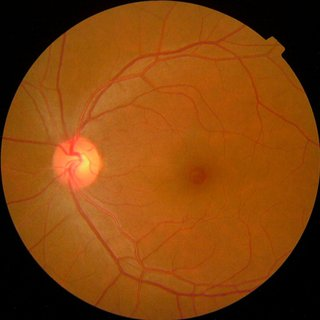
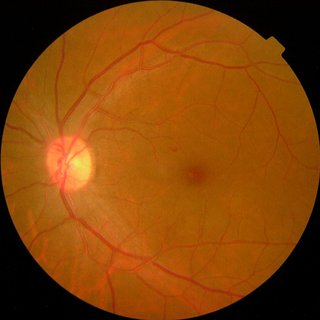
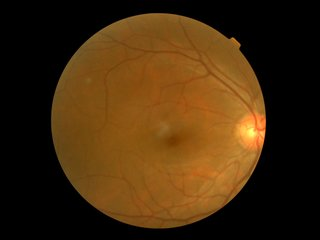
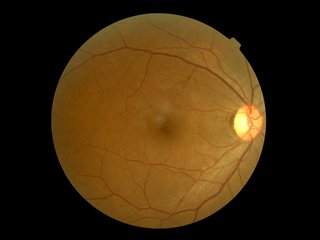
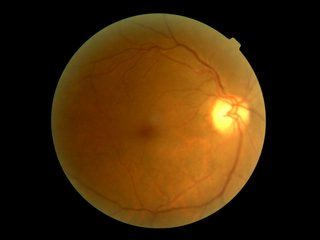
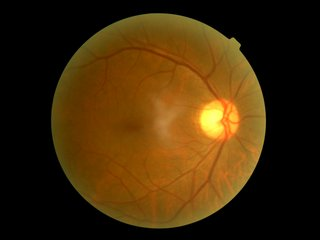
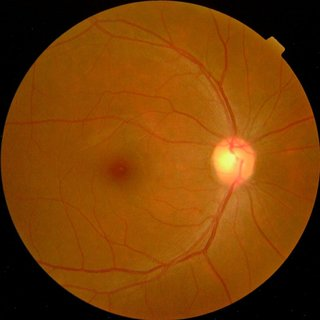
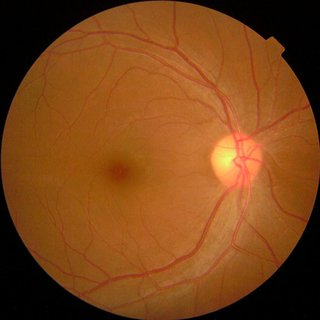
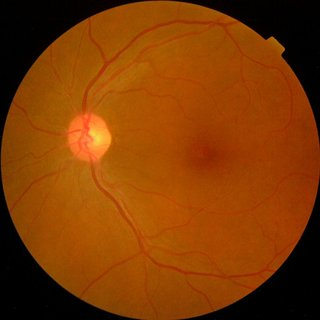
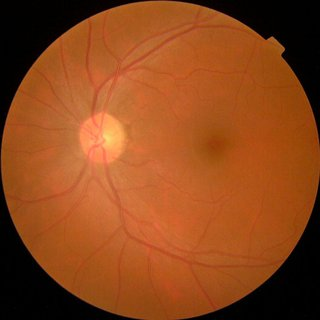
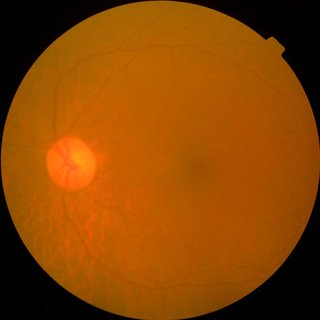
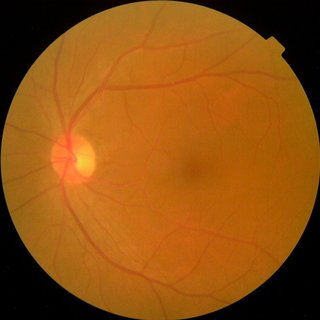
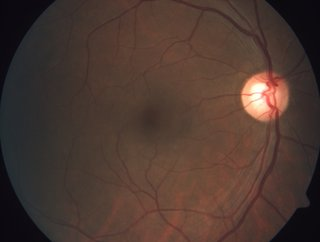
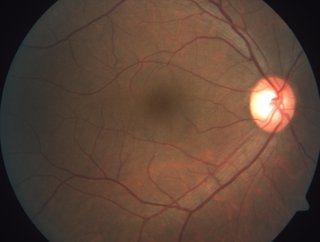
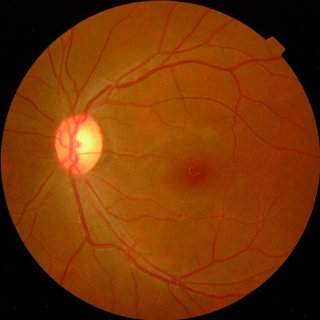
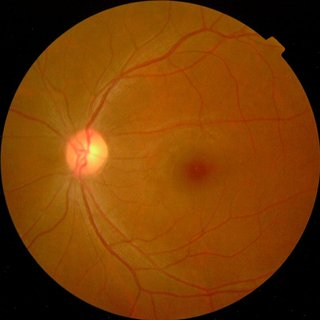
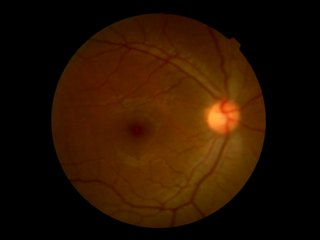
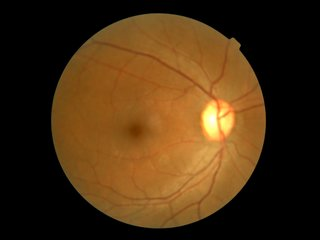
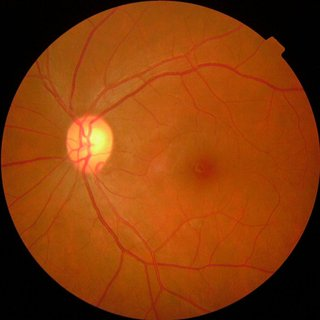
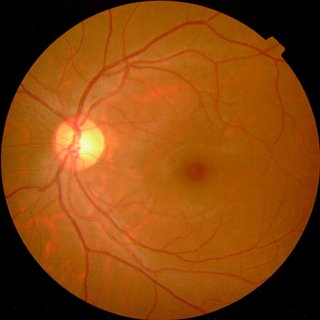
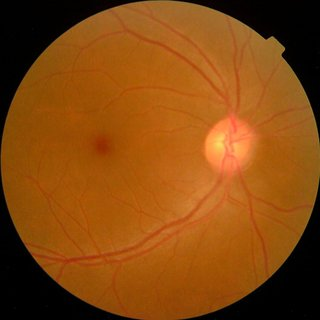
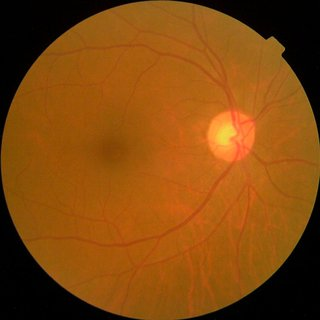
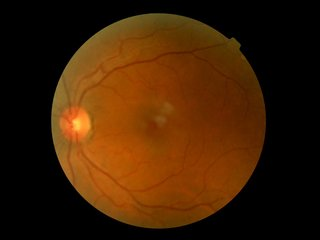
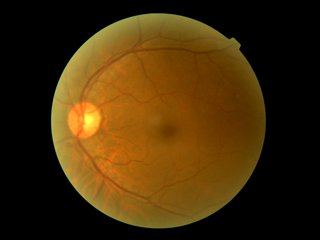
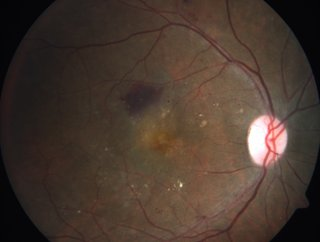
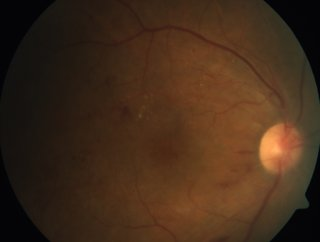
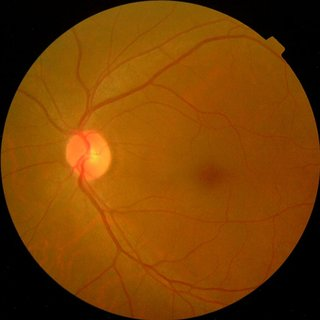
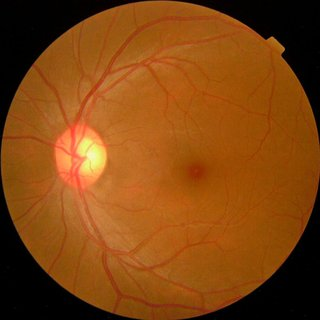
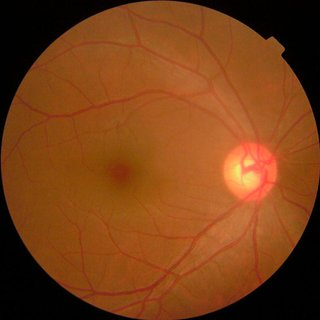
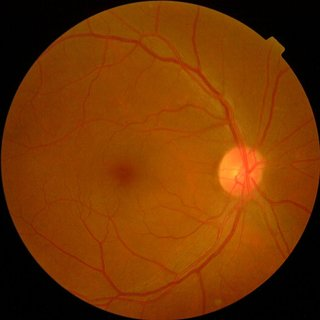
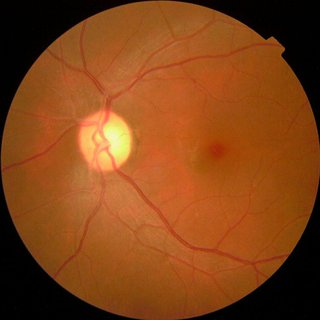
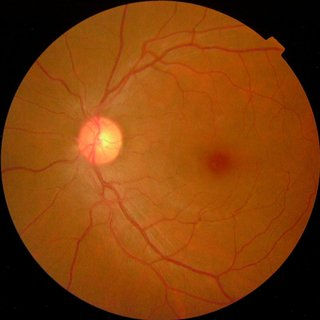
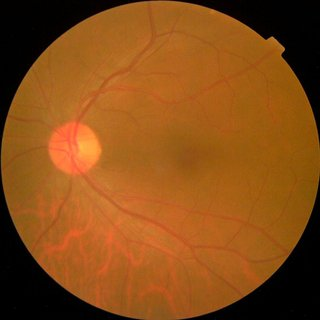
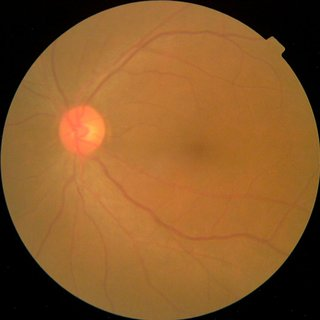
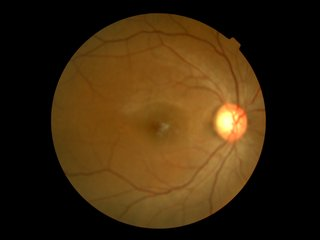
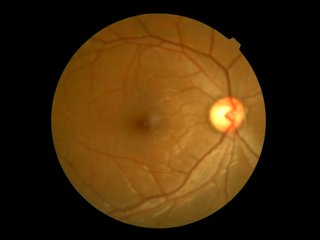
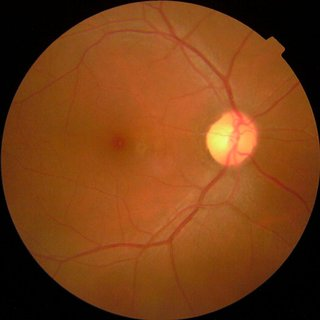
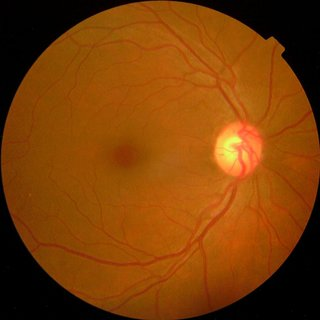
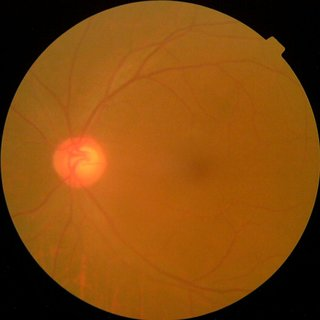
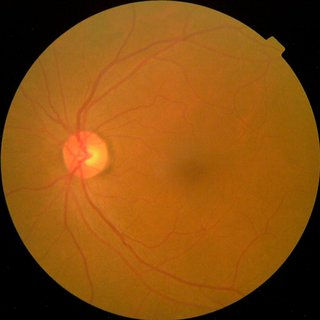
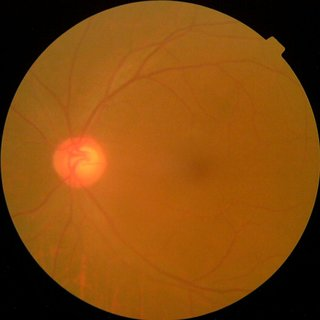
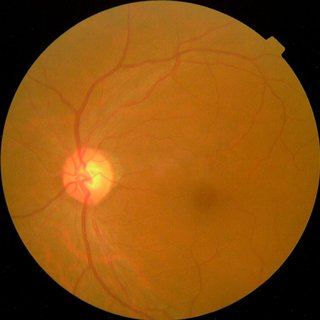
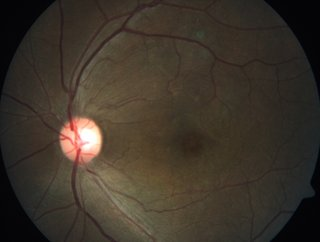
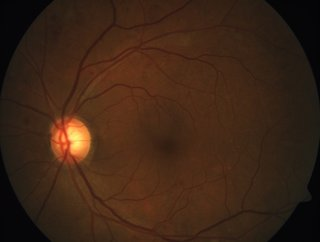
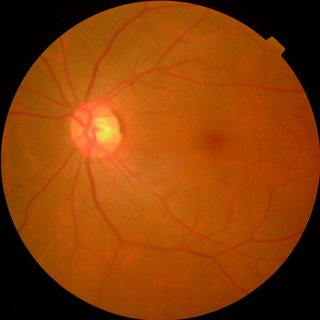
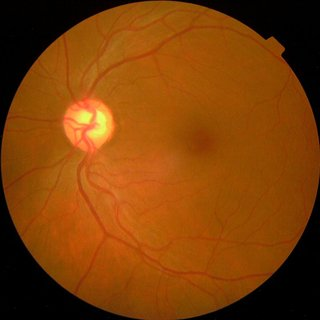
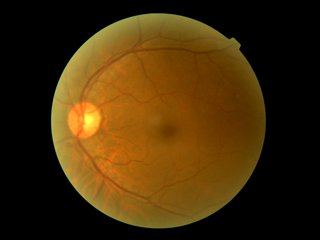
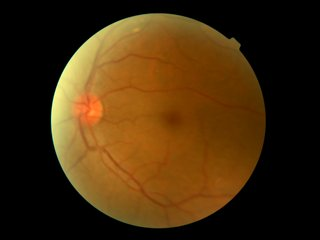
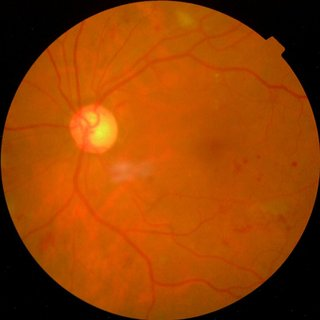
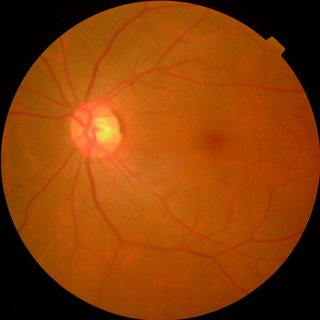
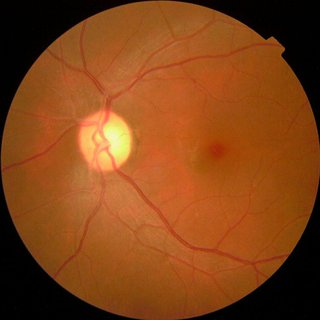
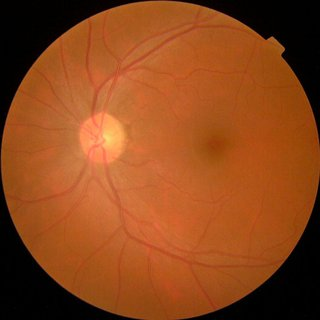
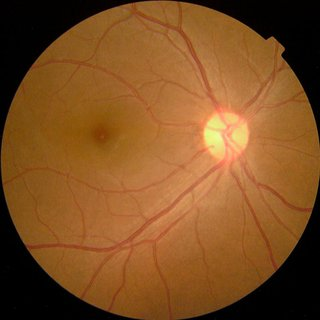
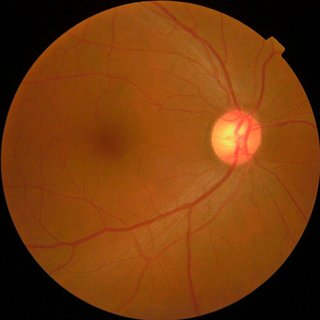
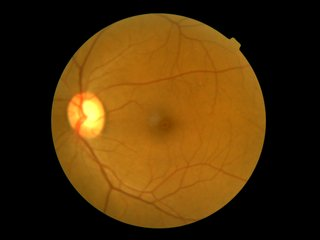
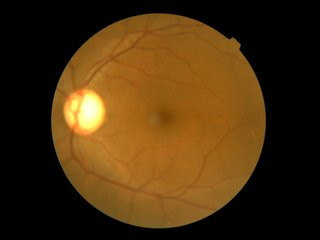
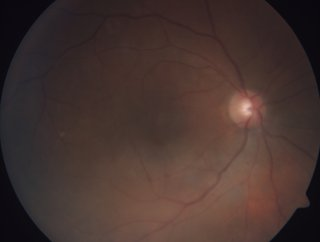
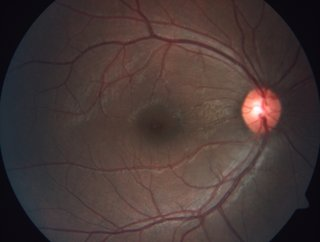
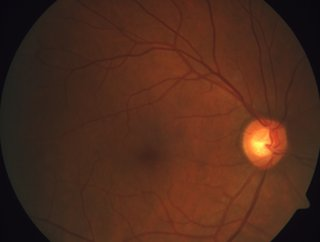
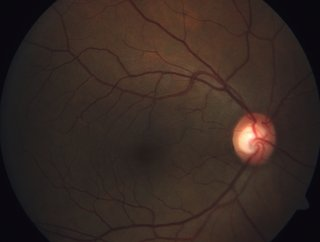
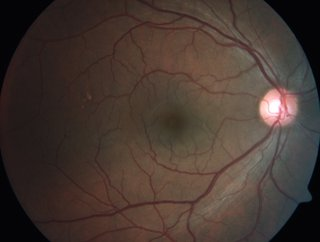
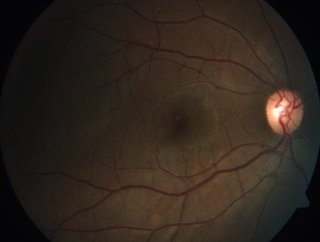
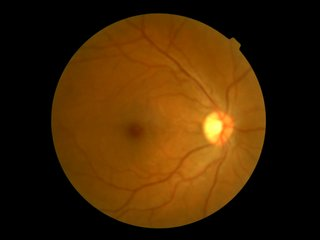
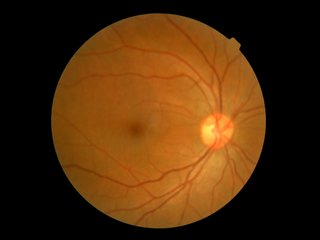
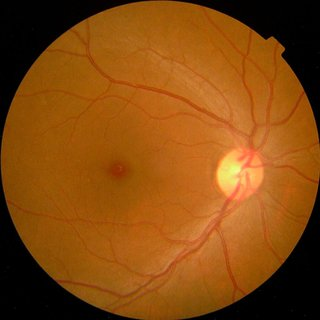
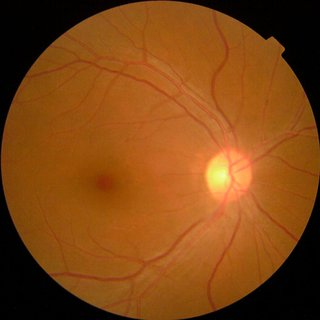
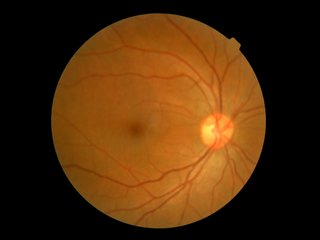
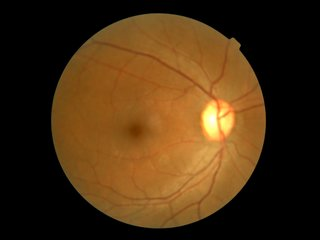
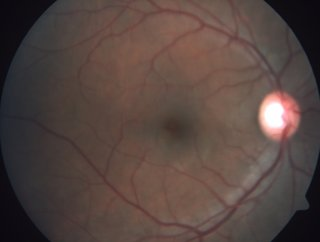
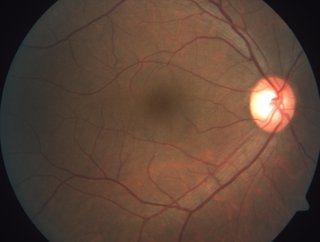
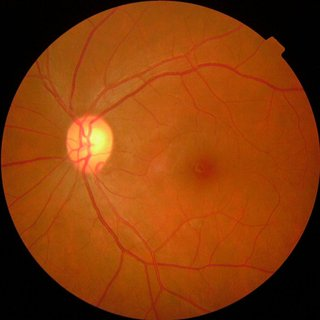
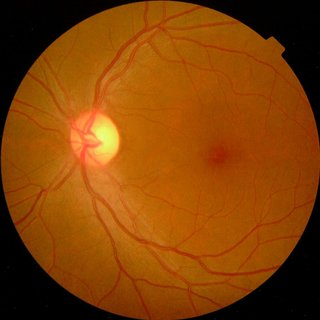
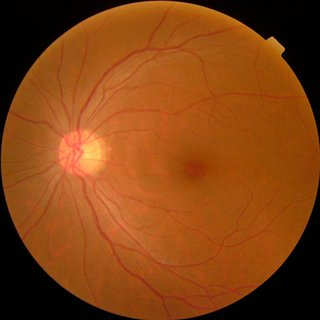
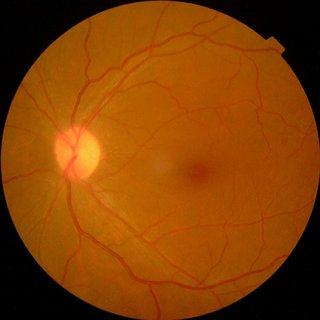
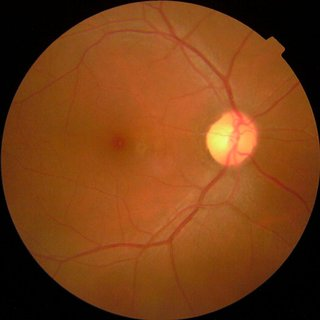
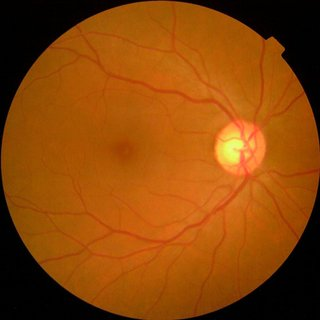
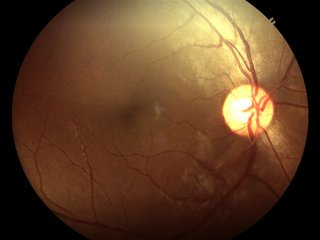
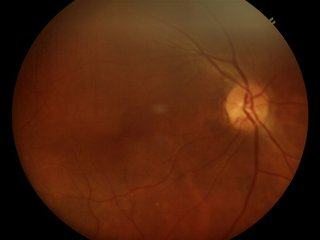
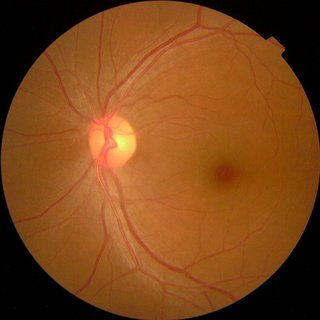
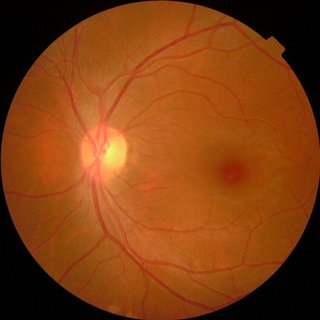
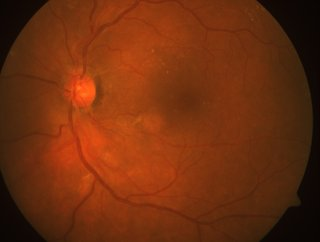
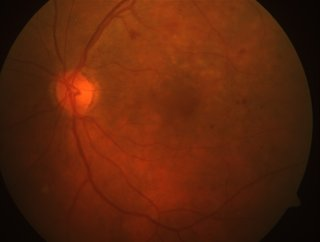
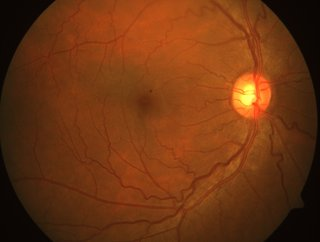
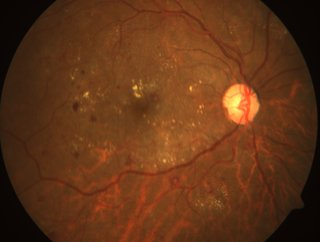
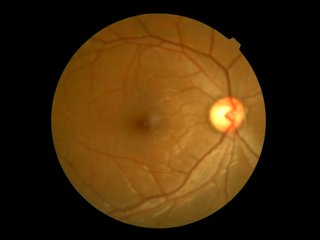
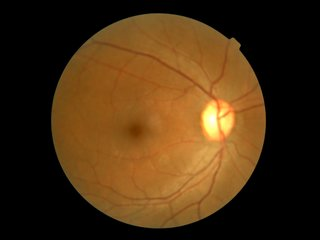
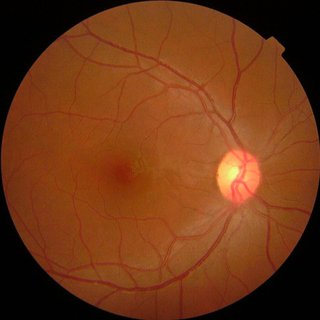
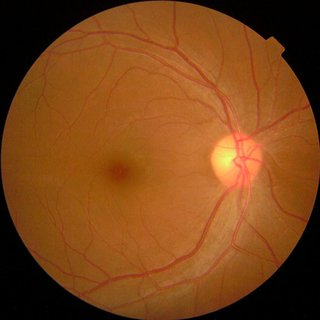
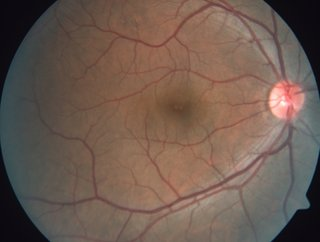
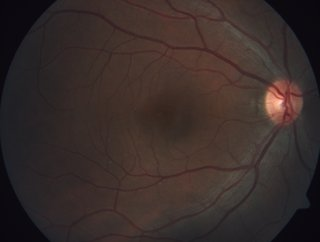
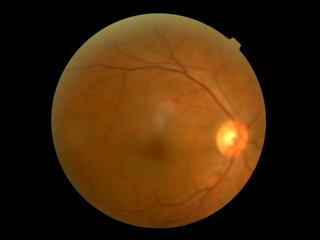
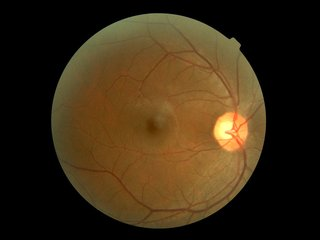
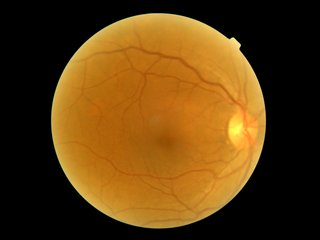
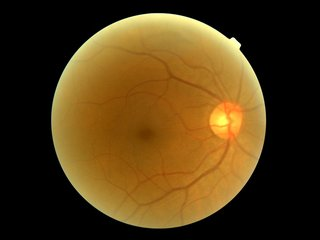
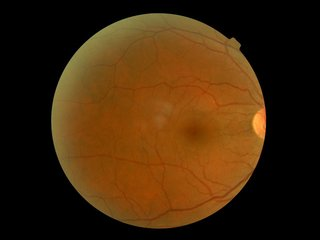
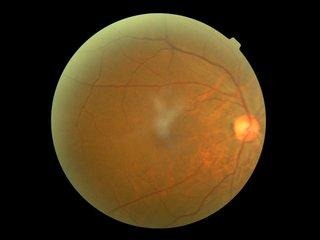
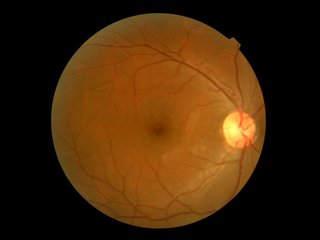
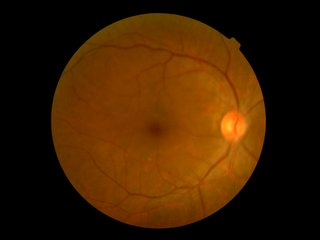
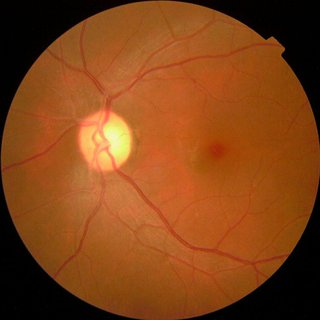
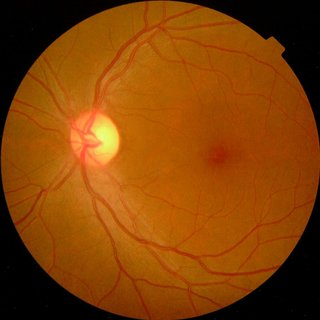

In [74]:

import pandas as pd
import numpy as np
import base64
import io
import html
from PIL import Image
from pathlib import Path
from IPython.display import HTML, display

# ============ CẤU HÌNH ============
OUT_DIR = Path("/kaggle/working/aptos_s0_v1_work")

MODE = "top1000"    # "top1000" hoặc "sample200"
PAGE = 3            # Trang 1, 2, 3, ...
PAGE_SIZE = 50       # 50 cặp/trang
IMAGE_SIZE = 320     # Kích thước ảnh hiển thị (px)

# ============ ĐỌC DỮ LIỆU ============
review_path = (
    OUT_DIR / "data_quality/near_duplicate_review_v1_template.csv"
)
manifest_path = (
    OUT_DIR / "data_quality/image_manifest.csv"
)

review = pd.read_csv(review_path, dtype={"id_1": str, "id_2": str})
manifest = pd.read_csv(manifest_path, dtype={"id_code": str})
manifest = manifest.set_index("id_code")

assert MODE in ["top1000", "sample200"]
assert PAGE >= 1

subset = (
    review[review["scope"] == MODE]
    .sort_values("rank")
    .reset_index(drop=True)
)

start = (PAGE - 1) * PAGE_SIZE
end = min(start + PAGE_SIZE, len(subset))

assert start < len(subset), "Trang không tồn tại!"

batch = subset.iloc[start:end]

# ============ ĐỌC ẢNH GỐC ============
def get_image_base64(image_id):
    path = Path(manifest.loc[image_id, "path"])

    if not path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy ảnh {image_id}: {path}. "
            "Hãy gắn lại dataset ảnh APTOS."
        )

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )

        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=85)

    return base64.b64encode(buffer.getvalue()).decode("ascii")

# ============ HIỂN THỊ ============
blocks = []

for row in batch.itertuples(index=False):
    image_a = get_image_base64(row.id_1)
    image_b = get_image_base64(row.id_2)

    id_a = html.escape(str(row.id_1))
    id_b = html.escape(str(row.id_2))
    pair_id = html.escape(str(row.pair_id))

    blocks.append(f"""
    <div style="
        border-bottom:2px solid #ccc;
        padding:20px 8px;
        margin-bottom:12px;
        font-family:Arial;
    ">
        <div style="font-weight:bold;font-size:17px;">
            Hạng {row.rank}
        </div>

        <div style="
            font-family:monospace;
            font-size:13px;
            margin:7px 0;
            user-select:text;
        ">pair_id: {pair_id}</div>

        <div style="display:flex;gap:20px;flex-wrap:wrap;">

            <div style="flex:1;min-width:240px;">
                <img src="data:image/jpeg;base64,{image_a}"
                     style="width:100%;max-width:{IMAGE_SIZE}px;
                            height:auto;">
                <pre style="
                    font-size:15px;
                    white-space:pre-wrap;
                    user-select:text;
                ">Ảnh A: {id_a}
Grade: {row.grade_1}</pre>
            </div>

            <div style="flex:1;min-width:240px;">
                <img src="data:image/jpeg;base64,{image_b}"
                     style="width:100%;max-width:{IMAGE_SIZE}px;
                            height:auto;">
                <pre style="
                    font-size:15px;
                    white-space:pre-wrap;
                    user-select:text;
                ">Ảnh B: {id_b}
Grade: {row.grade_2}</pre>
            </div>

        </div>
    </div>
    """)

print(f"Nhóm: {MODE}")
print(f"Trang: {PAGE}")
print(f"Hiển thị {len(batch)} cặp ảnh")
print(f"Vị trí: {start + 1} đến {end}/{len(subset)}")

display(HTML(
    '<div style="max-height:1300px;overflow-y:auto;">'
    + "".join(blocks)
    + "</div>"
))
